# MAOA organoids — Exp1 and Exp3 MEA activity

This notebook shows the **same analysis for two experiments**, one after the other, so they can be compared directly.
The two experiments are never pooled: every plot and every statistic is computed for one experiment only.

| | Experiment | Plates | Ages analysed |
|---|---|---|---|
| <span style="background:#E07A1F;color:white;padding:2px 8px;border-radius:4px;font-weight:bold">EXP1 · 2.4–4.8 months</span> | Exp1 | MAOA1, MAOA2, MAOA3 | 2.4–4.8 months (10 weekly recordings) |
| <span style="background:#1F5FA8;color:white;padding:2px 8px;border-radius:4px;font-weight:bold">EXP3 · 7.4–8.5 months</span> | Exp3 | MAOA72, MAOA76, MAOA77 (after the September re-plating) | 7.4–8.5 months (5 weekly recordings) |

**Colour code:** every block of results starts with a coloured banner, and every figure has the same coloured tag in its top-left corner.

**Contents**
1. Data preparation (steps 1–6): what was loaded, corrected and excluded, and why
2. How to read the figures and statistics
3. Summary table of the statistics
4. Results by feature: firing rate, burst rate, network event rate, synchrony index
5. Supplementary: the same analyses with each clone shown separately

This notebook only displays results. The PDF figures for the paper are saved by `spk_burs_net_analysis_figure.ipynb` (Exp3)
and `spk_burs_net_analysis_figure_exp1.ipynb` (Exp1). The full methods and the log of every analysis decision are in `README.md`.

In [1]:
# Setup: load the project's helper code and standard libraries
%load_ext autoreload
%autoreload 2

from helper_files.maoa_plate_loader import *    # loading, plate layouts, data cleaning
from helper_files.mea_feats_analysis import *   # plots and statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import warnings

# hide routine library warnings so the outputs stay readable
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

---
# 1. Data preparation

### Step 1 — Load the processed recordings
Each raw Axion spike list (one plate on one day) was already summarised into one row per well by
`spk_burs_net_analysis.ipynb`. Each row holds the well's firing rate, burst rate, network event rate and
synchrony index, plus the firing and burst rate of each of its 64 electrodes.

In [2]:
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'rb') as file:
    big_df = pickle.load(file)

print(f"{len(big_df)} well recordings, {big_df['plate_name'].nunique()} plates, "
      f"{big_df['recording_date'].nunique()} recording days")

1488 well recordings, 6 plates, 29 recording days


### Step 2 — Fix mislabelled and duplicate files
For a few recordings, the plate **folder** the file was saved in and the plate in the **file name** disagreed.
To find the true plate, each file's firing pattern across its 768 electrodes was compared with each plate's recordings
in the weeks before and after. A plate's pattern is stable from week to week: the same plate correlates at r ≈ 0.6–0.9,
a different plate at r ≈ 0.0–0.15.

| Date | Problem | Fix |
|---|---|---|
| 2025-08-22 | a plate 2 recording was saved in the MAOA3 folder | moved to MAOA2 |
| 2025-09-06 | a second recording of plate 2 was saved in the MAOA3 folder | moved to MAOA2 (then dropped as a duplicate) |
| 2025-09-19 | the MAOA2 and MAOA3 files were swapped | swapped back |
| 2025-10-16 | the plate 77 file is named "plate 76" | data is plate 77, no change needed |
| 2025-10-30 | each Exp3 plate was recorded twice that day | the first recording is kept |

Only the 2025-10-30 duplicate affects the data analysed here; the others fall outside both analysis windows.

In [3]:
# Reassign misfiled recordings to their true plate (clone labels are re-read from that plate's layout)
# and keep one recording per well per day
big_df = clean_recordings(big_df)

08.22.2025: 12 wells moved MAOA3 -> MAOA2
09.06.2025: 12 wells moved MAOA3 -> MAOA2
09.19.2025: 12 wells moved MAOA2 -> MAOA3
09.19.2025: 12 wells moved MAOA3 -> MAOA2
Dropped 48 duplicate well recordings (kept first recording of the day).


### Step 3 — Label each recording with its experiment
- **Exp1**: plates MAOA1–3
- **Exp2**: plates MAOA72/76/77 before 2025-09-25 (not used here)
- **Exp3**: plates MAOA72/76/77 from 2025-09-25, after re-plating into the new layout

In [4]:
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]), axis=1)
big_df["recording_date"] = pd.to_datetime(big_df["recording_date"], errors="coerce")

### Step 4 — Remove bad recording days and detached wells
| What | Why |
|---|---|
| Recording day 2025-09-26 | bad recording |
| Recording day 2025-05-09 | noise artefact: every electrode in every well fired at ~0.8 Hz, about 80× the weeks before and after, including the normally silent KO wells, while synchrony fell to ~0 |
| Well MAOA76 A4 (GM) in Exp3 | the organoid detached at the September re-plating; the well was near-silent at every Exp3 recording (0–5 of 64 electrodes active) |

The lists live in `helper_files/maoa_plate_loader.py`, so all notebooks use the same exclusions.

In [5]:
# The lists and the reason for each are in helper_files/maoa_plate_loader.py (BAD_RECORDING_DATES, EXCLUDED_WELLS)
big_df = apply_exclusions(big_df)

2025-09-26: removed 36 well recordings (bad recording)
2025-05-09: removed 36 well recordings (noise artefact: every electrode in every well fires ~0.8 Hz (~80x the neighbouring weeks), incl. normally silent KO wells; synchrony ~0)
MAOA76 A4 from 2025-09-25: removed 5 well recordings (GM organoid detached at the Sept re-plating; near-silent (0-5/64 active electrodes))


### Step 5 — Keep only the clones used in this analysis
| Genotype group (figure label) | Clones |
|---|---|
| Xa:WT/Xi:MUT | C30 |
| Xa:MUT/Xi:WT | C71, C3 |
| MAOA/B⁻/Y (KO) | GM |

All other clones (H9, C12, C54, C90) are removed. C3 is also removed from MAOA2 and MAOA3, so in Exp1 C3 comes from MAOA1 only.

In [6]:
# clones removed from each plate
REMOVALS = {
    "MAOA1":  {"H9", "C12", "C54", "C90"},
    "MAOA2":  {"H9", "C12", "C3", "C54", "C90"},
    "MAOA3":  {"H9", "C12", "C3", "C54", "C90"},
    "MAOA72": {"C12", "C90", "C54"},
    "MAOA76": {"C12", "C90", "C54"},
    "MAOA77": {"C12", "C90", "C54"},
}
big_df = remove_clones_by_plate(big_df, REMOVALS)

Removed 402 rows based on plate-specific clone removal.


### Step 6 — Keep only the ages with good data
The same rule is applied to both experiments: a recording day counts as good if **at least 40 % of wells are active**
(well firing rate ≥ 5 spikes/min). The analysis window runs from the first recording up to the first day that fails.

- **Exp3**: every day passes, so all 5 recordings are used.
- **Exp1**: the window ends after 4.8 months, when only 30 % of wells are still active.

The drop in active wells is driven mainly by the KO wells going silent, while both heterozygous groups stay active.
The same KO silencing is seen in Exp3 from about 7.8 months, so it is treated as part of the phenotype, not as bad data.

In [7]:
# Good-data window of each experiment (rule: >= 40% of wells active, up to the first day that fails)
datasets, quality = get_experiment_datasets(big_df, experiments=("Exp1", "Exp3"), min_active_frac=0.40)

print("Exp1: fraction of active wells per recording day  [good = used in the analysis]")
display(quality["Exp1"].round(2))
print("\nExp3")
display(quality["Exp3"].round(2))

Exp1: fraction of active wells per recording day  [good = used in the analysis]


,age_months,n_wells,active_frac,good
recording_date,,,,
2025-04-14,2.4,20,0.95,True
2025-04-18,2.5,20,0.95,True
2025-04-21,2.6,20,0.95,True
2025-04-25,2.8,20,0.95,True
2025-05-02,3.0,20,0.95,True
2025-05-16,3.4,20,0.95,True
2025-05-30,3.9,20,0.55,True
2025-06-13,4.4,20,0.40,True
2025-06-20,4.6,20,0.40,True



Exp3


,age_months,n_wells,active_frac,good
recording_date,,,,
2025-09-25,7.4,21,0.86,True
2025-10-02,7.6,21,0.90,True
2025-10-09,7.8,21,0.81,True
2025-10-16,8.0,21,0.62,True
2025-10-30,8.5,21,0.52,True


### The data analysed
Number of wells in each genotype group. Each well is recorded on every day in the window.

In [8]:
display(wells_per_group_table(datasets))

,recording days,ages (months),MAOA/B$^{-/Y}$,Xa:MUT/Xi:WT,Xa:WT/Xi:MUT,total wells
experiment,,,,,,
Exp1,10,2.4–4.8,9,6,5,20
Exp3,5,7.4–8.5,5,12,4,21


---
# 2. How to read the figures and statistics

Each feature in section 4 produces, for each experiment: **trajectory plots → significance matrices (if any) → printed statistics**, then **bar plots → printed statistics**.

### Trajectory plots — *how does activity change with age in each group?*
- **x-axis**: organoid age in months, one position per recording day. Positions are evenly spaced even when the gaps between recordings are not.
- **y-axis**: the feature (Hz for rates; unitless for synchrony).
- **Boxes**: one per genotype per age. Line = median, box = middle 50 % of values, whiskers = range excluding outliers.
- **Grey dots**: every individual observation, including outliers. *Well-Level* plots have one dot per well per day; *Electrode-Level* plots have one dot per active electrode per day.
- **Dashed line + shaded band**: a straight-line fit of each group's values against age, with its 95 % confidence band. It is a visual guide to the overall direction only, not a statistical test, and it can dip below 0 where values are close to 0.
- **"Trajectory" box** (top right): the result of the **group × age** test, which asks *do the groups change differently with age?* "ns" means the groups follow parallel courses, even if they differ in level.
- **Electrode-level plots have a broken y-axis**: the large lower panel is zoomed in (firing up to 11 Hz, burst up to 0.25 Hz) so the boxes are readable, and the small upper panel shows the few electrodes above that.

### Significance matrices — *which groups differ overall?*
Drawn after a trajectory plot only when the overall group effect is significant. Each cell compares the row group with
the column group across all ages together (the same test as the "Overall group differences" table). A coloured cell with
stars = significant difference; a pale cell with "ns" = not significant. The grid is symmetric, and the grey diagonal is a group compared with itself.

### Bar plots — *how do the groups compare on average?*
- **Bar** = mean of all observations across every age in the window; **error bar** = SEM; **dots** = individual observations.
- **Stars between bars** = the overall pairwise group test (same numbers as the "Overall group differences" table).
- The SEM is descriptive only: it treats every well-day as independent. The stars come from the mixed model, which accounts for each well being recorded repeatedly.

### Printed statistics — what each part means
Example (Exp1, well-level firing):
```
--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.56e-05 ****      <- do the groups differ overall (averaged over ages)?
        age 1.68e-70 ****      <- does the feature change with age (all groups together)?
group x age   0.0132    *      <- do the groups change differently with age? (= "Trajectory" box)
Overall group differences (Holm):
        group1       group2    diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.364    3e-07 ****   <- one row per pair of groups
...
Per-age group differences (Holm across all ages x pairs):
 Time   <pair 1>   <pair 2>   <pair 3>               <- one row per age, stars for each pair at that age
  2.4       ****       ****         ns
```
- **Header**: the level (well or electrode), the feature, the model used, **n** = number of observations, **wells** = number of different wells.
- **term / p / sig**: likelihood-ratio tests from the mixed model (see below). Each p-value comes from comparing a model with that term against one without it.
- **diff**: group2 minus group1, in the units the model uses (square root of Hz for firing, burst and network; raw index for synchrony).
  **Positive = group2 is higher.** Use the sign for direction, and the plots for size in real units.
- **p-adj**: p-value corrected for testing three pairs (Holm).
- **Per-age table**: the same pairwise comparisons at each single age, corrected for all ages × pairs together. This is stricter than testing each age on its own, so a difference visible in the plot at one age can still be "ns" here.
- Under the bar plots the block is labelled "(BAR PLOT)". It repeats the overall test, and its pairwise rows give the bar stars.
- Stars: \* p < 0.05, \*\* p < 0.01, \*\*\* p < 0.001, \*\*\*\* p < 0.0001, ns = not significant.

### The statistical model, in plain terms
- **Why a mixed model.** The same wells are recorded every week, and electrodes sit inside wells, so the observations are not independent. A standard ANOVA would count every week of every well as new evidence and make p-values far too small. The mixed model gives each well (and, at electrode level, each electrode) its own baseline ("random intercept"), so repeated recordings of the same well count as repeated measures of one unit.
- **Fixed effects.** Group, age (each recording day as its own category), their interaction, and plate (to absorb plate-to-plate differences).
- **Transform.** Rates are strongly right-skewed (a few very active wells), so firing, burst and network rates are square-root transformed before testing. Plots always show the untransformed values.
- **Well level vs electrode level.** Well level (one value per well per day) is the main analysis. Electrode level (firing and burst only) uses every active electrode and asks the same questions at finer resolution; the model accounts for electrodes belonging to the same well.


In [9]:
# Genotype colours for the trajectory plots (same as the paper figures)
MAOA_FIGURE_PALETTE = {
    "Xa:WT/Xi:MUT": "#9C899C",
    "Xa:MUT/Xi:WT": "#EAC3EB",
    "MAOA/B$^{-/Y}$": "#E980C0",
}

---
# 3. Summary table of the statistics
One row per feature and experiment, well level. **trajectory** = the group × age test; the other columns are the
overall pairwise group differences (all ages pooled, Holm-corrected). These are the same numbers printed under the
plots in section 4; see section 2 for what each test means.

In [10]:
display(stats_summary_table(datasets))

trajectory      KO vs MUT/WT      KO vs WT/MUT  \
feature   experiment                                                  
firing    Exp1                *    **** (p=3e-07)  **** (p=7.9e-05)   
          Exp3                *  **** (p=2.4e-08)  **** (p=4.2e-13)   
burst     Exp1             ****   *** (p=0.00069)     ** (p=0.0049)   
          Exp3               **     ** (p=0.0014)  **** (p=9.2e-08)   
network   Exp1                *       * (p=0.011)   *** (p=0.00083)   
          Exp3               **   *** (p=0.00094)  **** (p=1.3e-08)   
synchrony Exp1             ****   *** (p=0.00048)  **** (p=6.7e-05)   
          Exp3               ns       ns (p=0.17)       * (p=0.023)   

                     MUT/WT vs WT/MUT  
feature   experiment                   
firing    Exp1            ns (p=0.37)  
          Exp3        *** (p=0.00091)  
burst     Exp1            ns (p=0.66)  
          Exp3          ** (p=0.0011)  
network   Exp1            ns (p=0.36)  
          Exp3        *** (p=0.00034)  
synchrony Exp1            ns (p=0.49)  
          Exp3            ns (p=0.17)

---
# 4. Results by feature
For each feature: the trajectory plots (Exp1, then Exp3), then the bar plots (Exp1, then Exp3).

## 4.1 Firing rate
**What it measures:** spikes per second. Well value = mean over the well's electrodes with at least one spike. Electrode-level plots include only electrodes firing ≥ 5 spikes/min.

**What to look at:** the y-axis is in Hz; higher = more spiking. There are two trajectory plots per experiment (well level, then electrode level with a broken axis) and two bar plots.

#### Trajectory across age
Outputs per experiment: trajectory plot(s) → significance matrix if the overall group effect is significant → printed statistics (group, age and group × age tests; overall pairs; per-age pairs).


FEATURE: FIRING


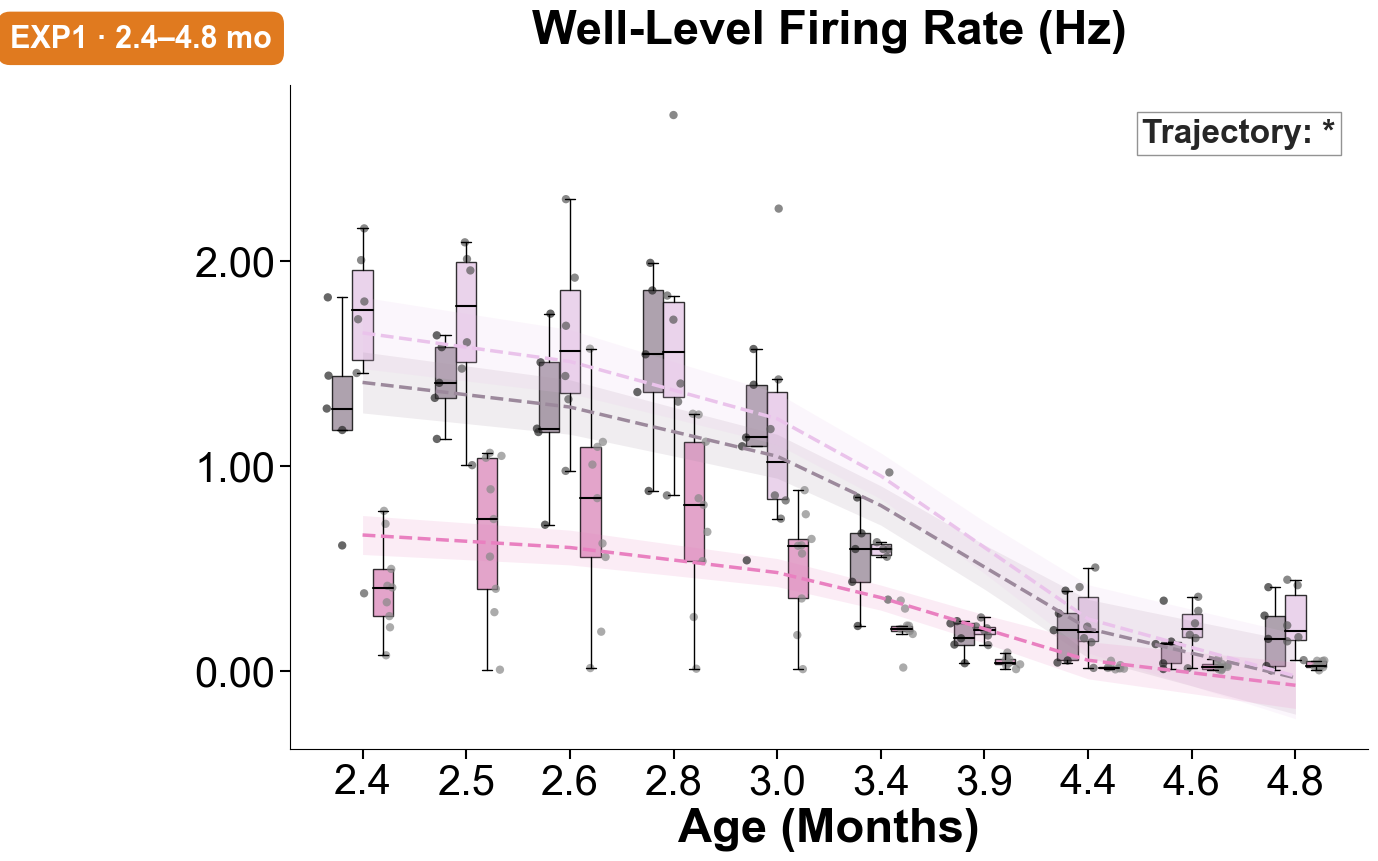

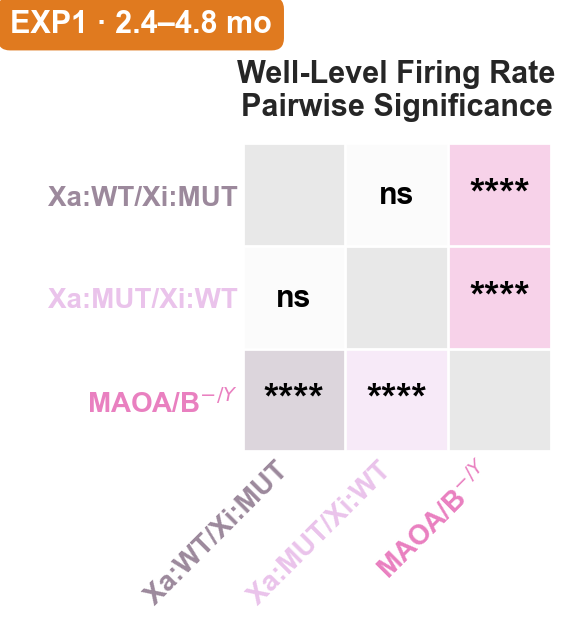

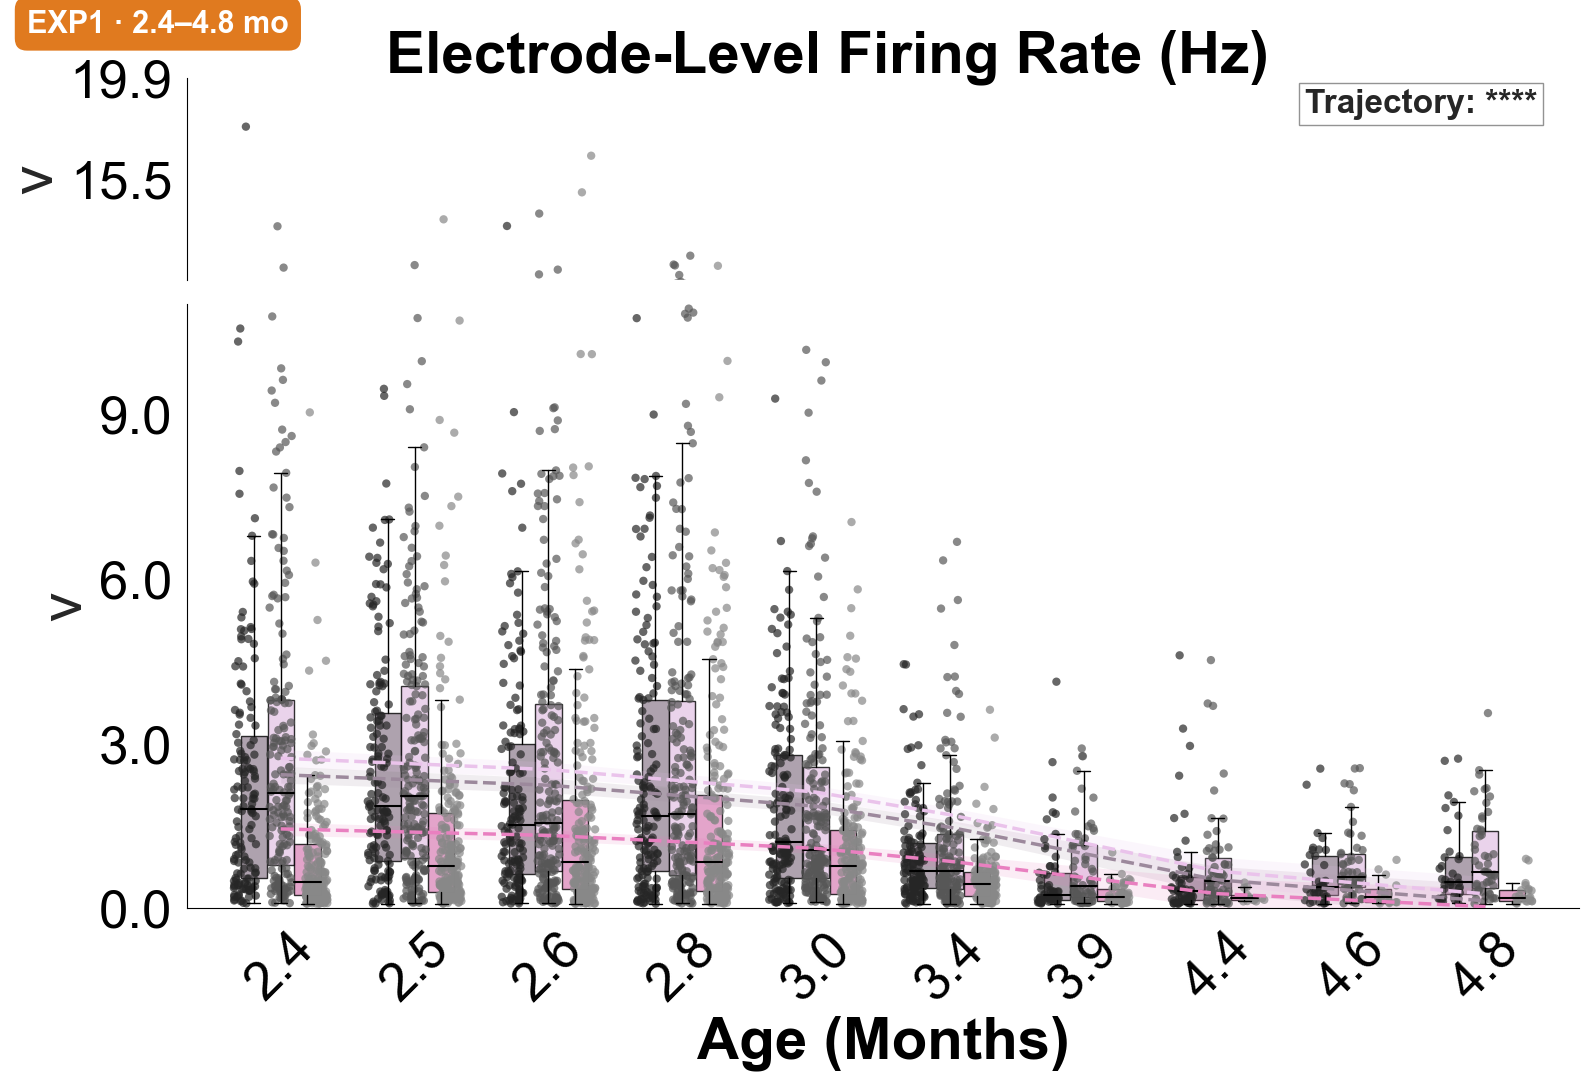

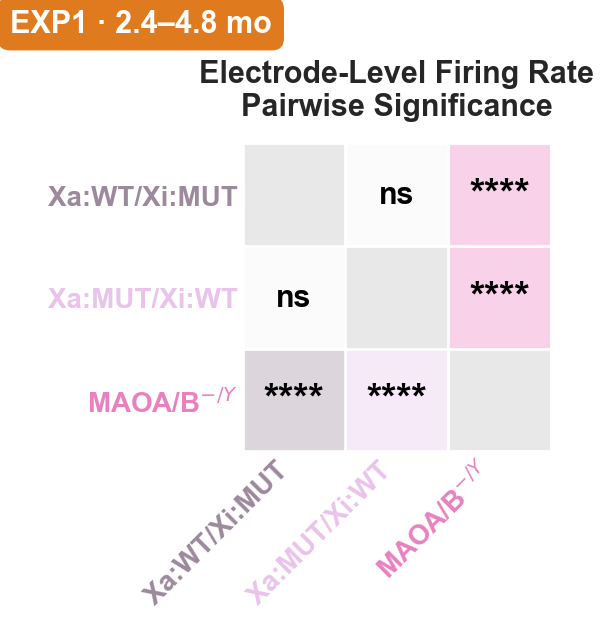


--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.56e-05 ****
        age 1.68e-70 ****
group x age   0.0132    *
Overall group differences (Holm):
        group1       group2    diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.364    3e-07 ****
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.294 7.87e-05 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.0692    0.371   ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                           ****                           ****                           ns
  2.5                           ****                            ***                           ns
  2.6                            ***                             ns                           ns
  2.8                            ***                             **                           ns
  3.0                             


FEATURE: FIRING


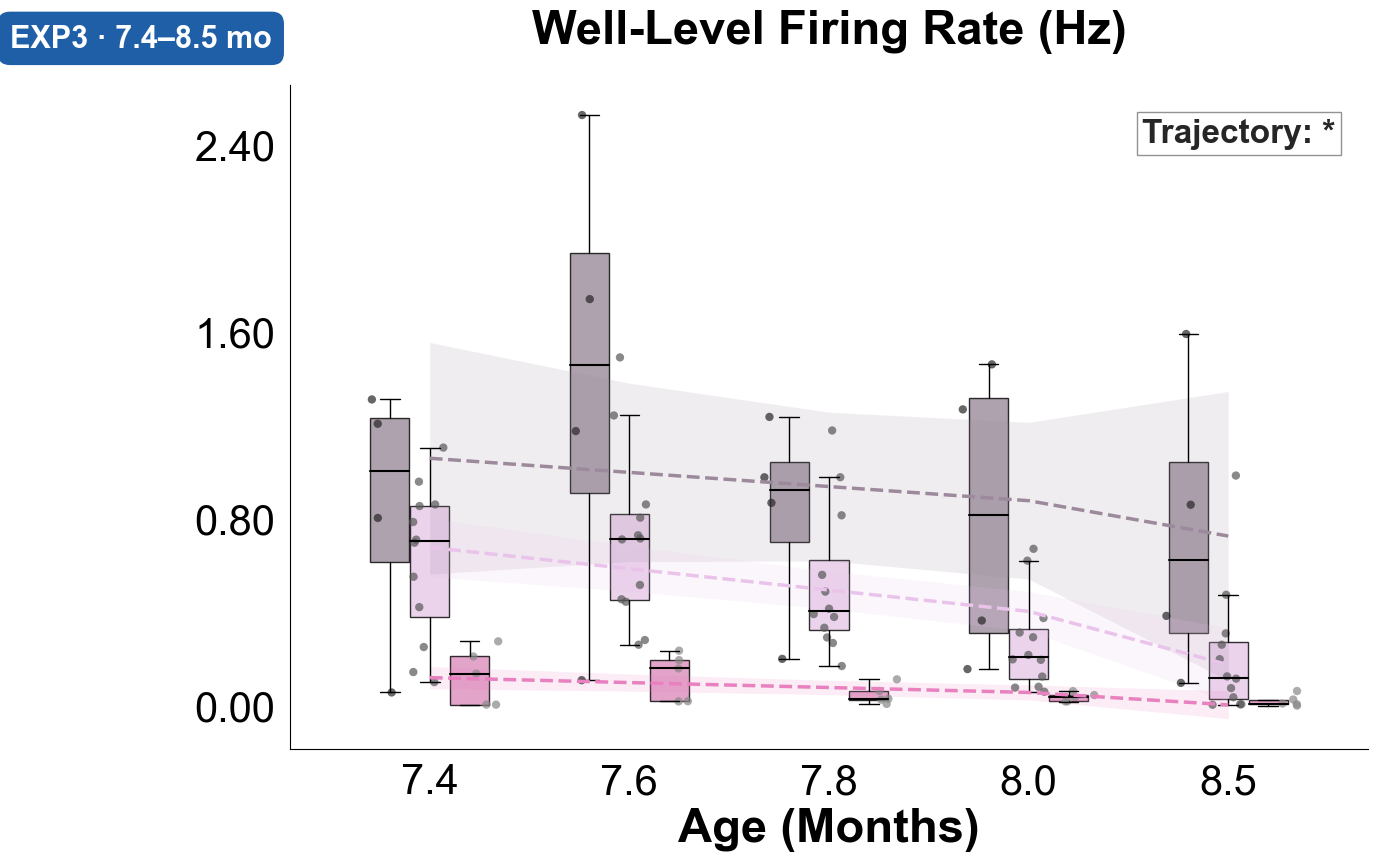

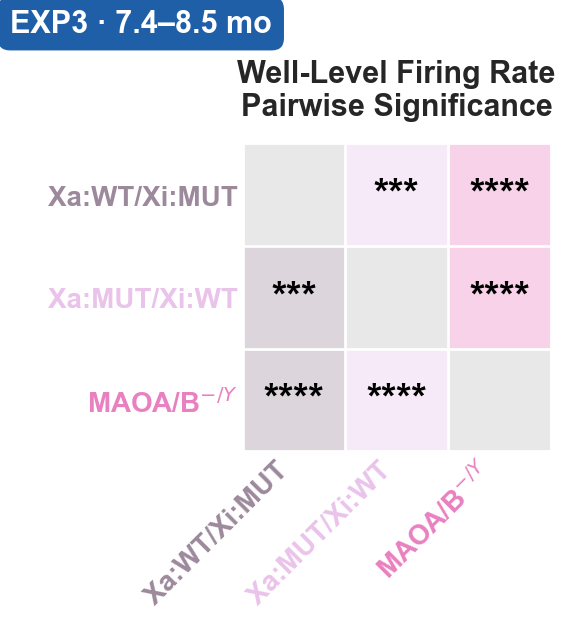

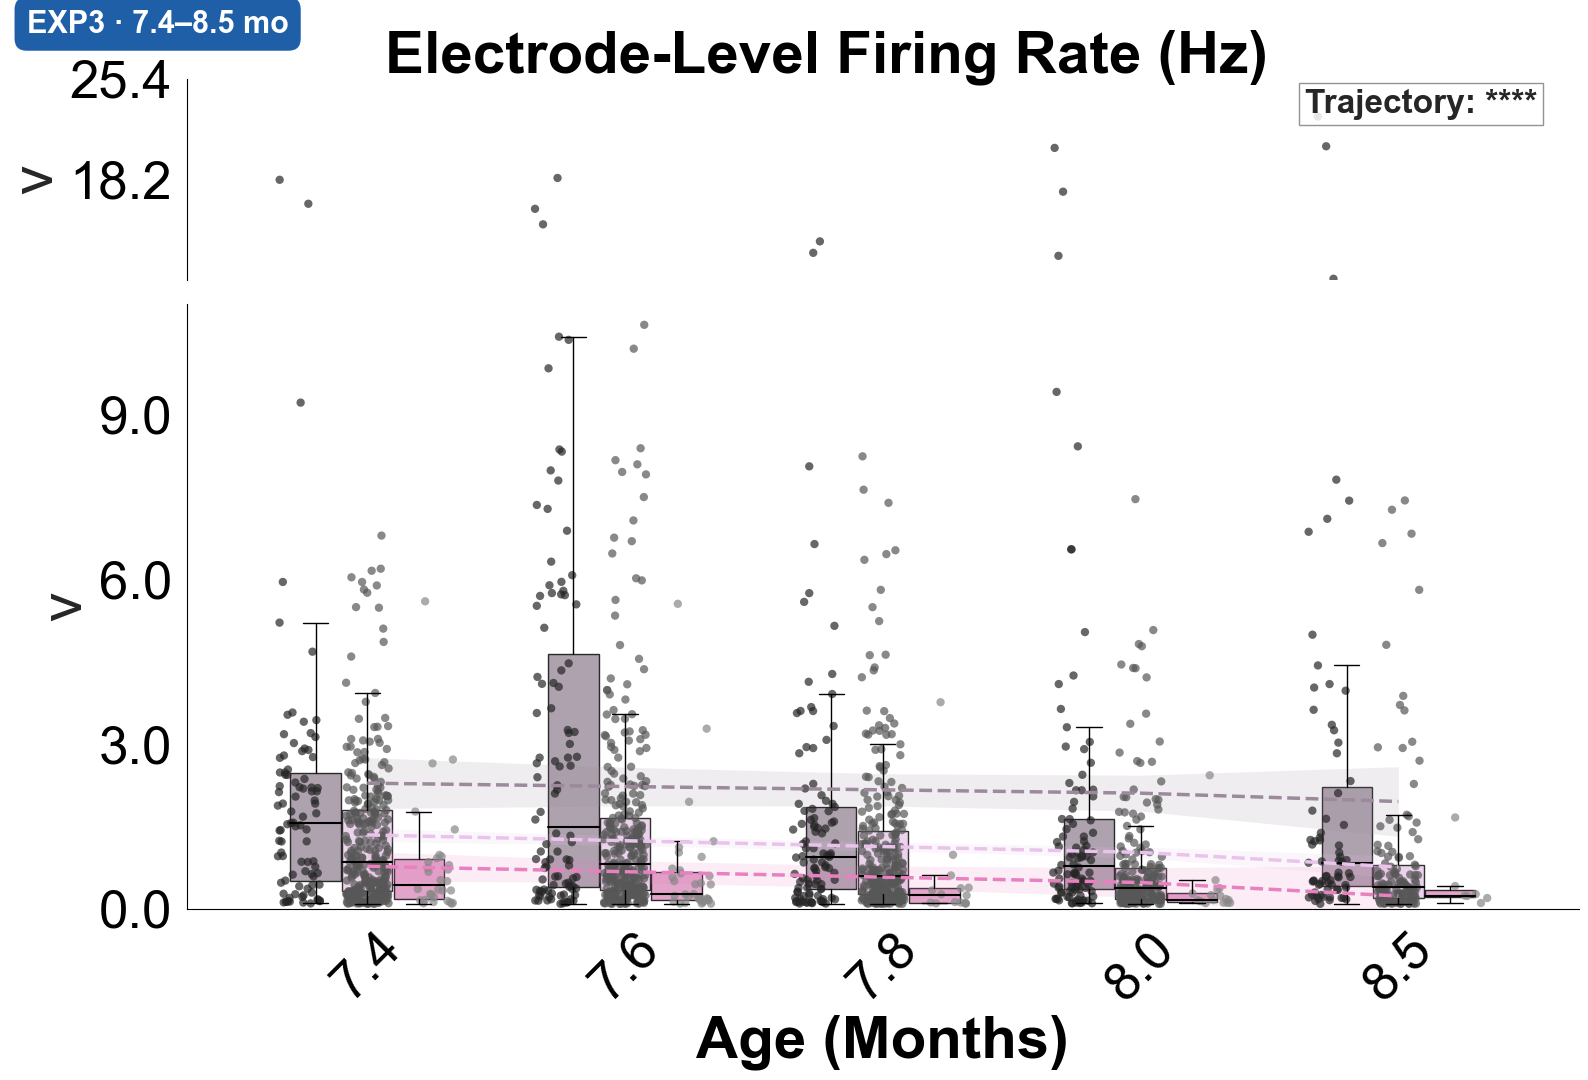

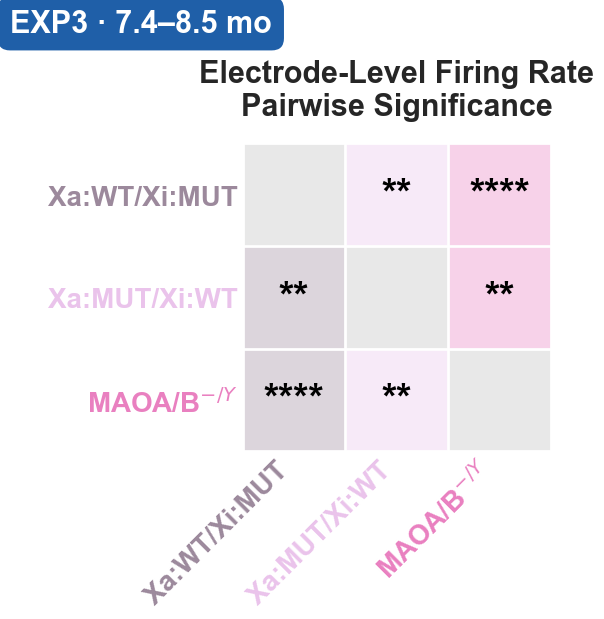


--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 8.71e-07 ****
        age 2.04e-12 ****
group x age   0.0172    *
Overall group differences (Holm):
        group1       group2  diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.367 2.36e-08 ****
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.599  4.2e-13 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.232 0.000914  ***
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                           ****                           ****                           ns
  7.6                           ****                           ****                            *
  7.8                           ****                           ****                           ns
  8.0                              *                           ****                           **
  8.5                              *      

In [11]:
show_feature_by_experiment(datasets, "firing", "trajectory", palette=MAOA_FIGURE_PALETTE)

#### Overall group differences (all ages pooled)
Outputs per experiment: bar plot(s), then the "(BAR PLOT)" statistics block whose pairwise rows give the stars above the bars.


--- GENERATING GROUPED PLOTS FOR FIRING ---


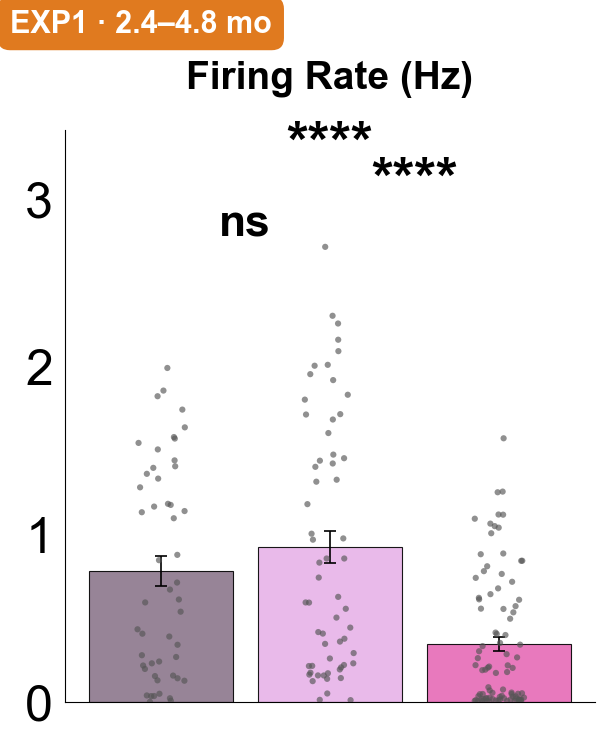

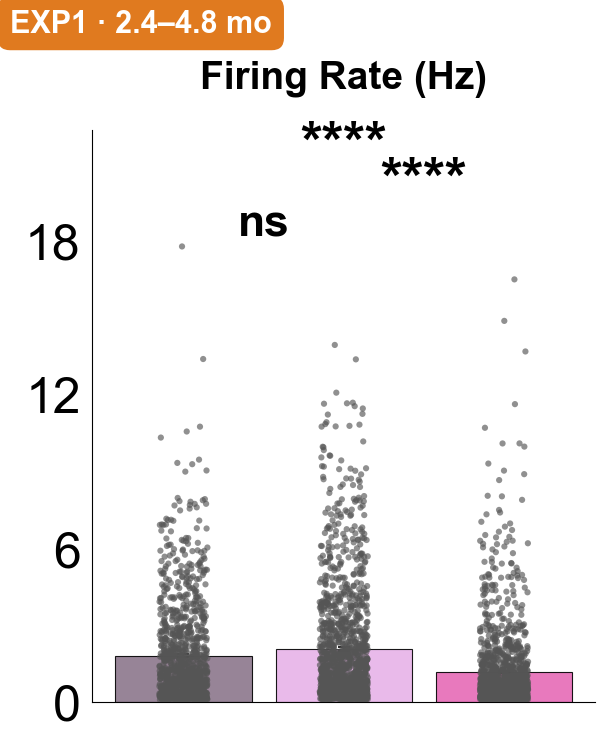


--- WELL-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.56e-05 ****
        age 1.68e-70 ****
group x age   0.0132    *
Overall group differences (Holm):
        group1       group2    diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.364    3e-07 ****
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.294 7.87e-05 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.0692    0.371   ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                           ****                           ****                           ns
  2.5                           ****                            ***                           ns
  2.6                            ***                             ns                           ns
  2.8                            ***                             **                           ns
  3.0                  


--- GENERATING GROUPED PLOTS FOR FIRING ---


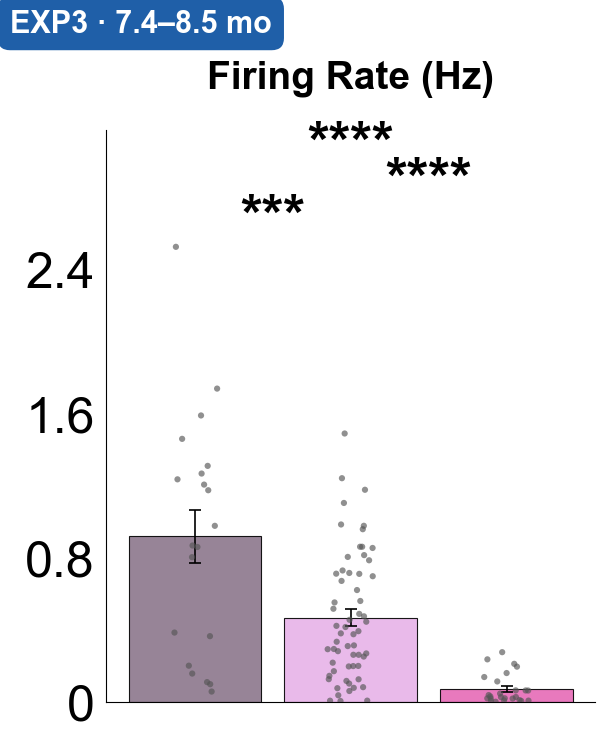

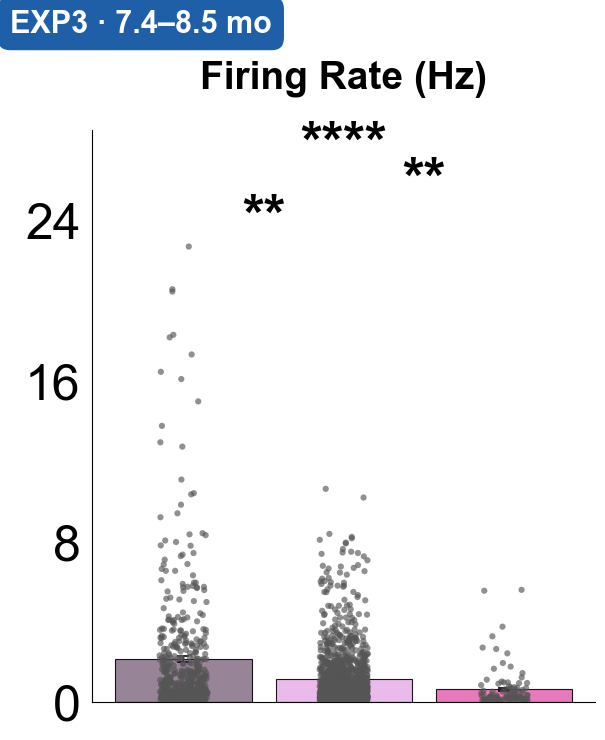


--- WELL-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 8.71e-07 ****
        age 2.04e-12 ****
group x age   0.0172    *
Overall group differences (Holm):
        group1       group2  diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.367 2.36e-08 ****
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.599  4.2e-13 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.232 0.000914  ***
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                           ****                           ****                           ns
  7.6                           ****                           ****                            *
  7.8                           ****                           ****                           ns
  8.0                              *                           ****                           **
  8.5                          

In [12]:
show_feature_by_experiment(datasets, "firing", "bars", palette=MAOA_FIGURE_PALETTE)

## 4.2 Burst rate
**What it measures:** bursts per second. A burst is ≥ 5 spikes in a row on one electrode with every gap ≤ 100 ms. Well value = mean over the well's bursting electrodes.

**What to look at:** the y-axis is in Hz (bursts/s). Wells with no bursting electrode have no value and are left out. There are well-level and electrode-level plots, as for firing.

#### Trajectory across age
Outputs per experiment: trajectory plot(s) → significance matrix if the overall group effect is significant → printed statistics (group, age and group × age tests; overall pairs; per-age pairs).


FEATURE: BURST


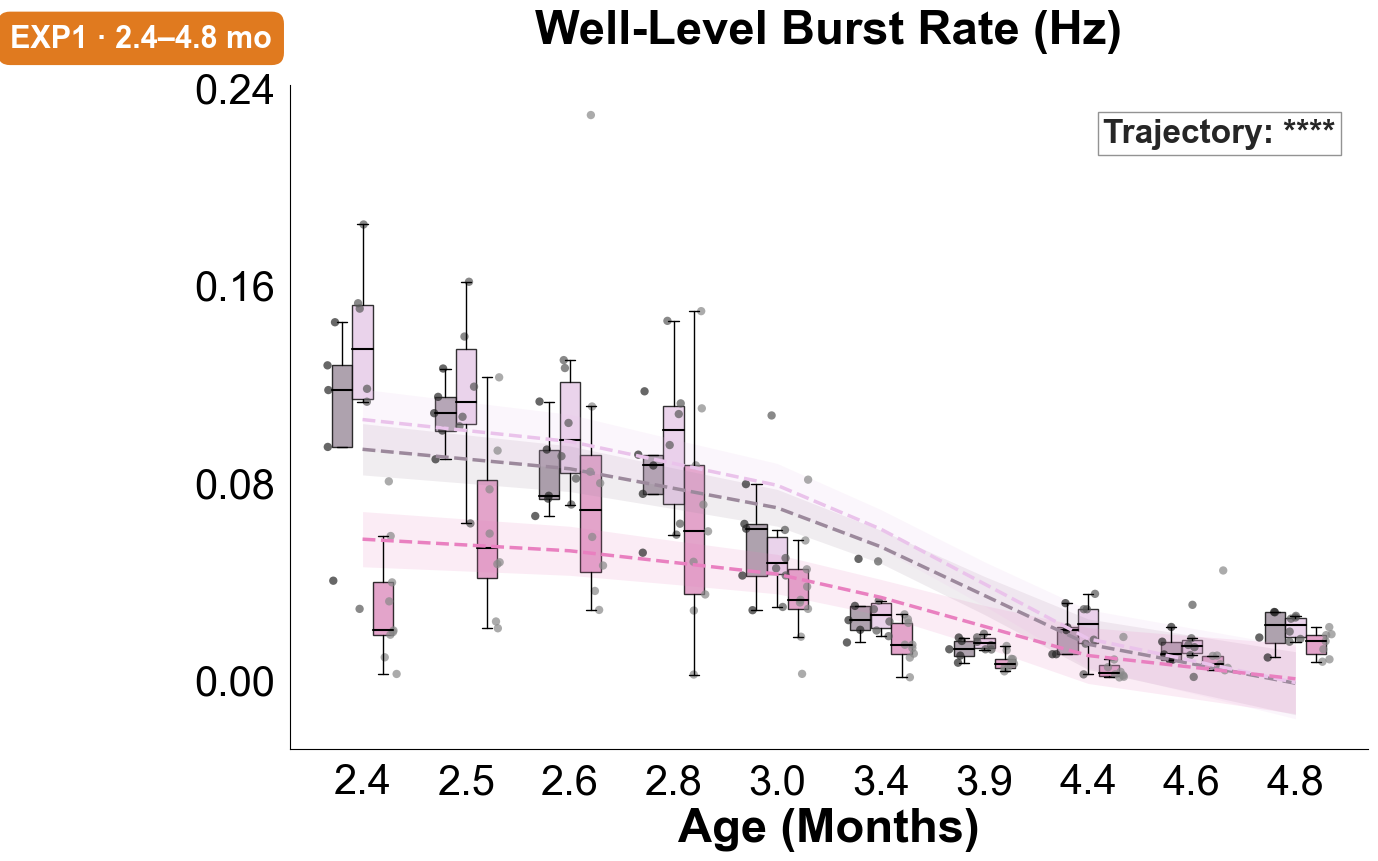

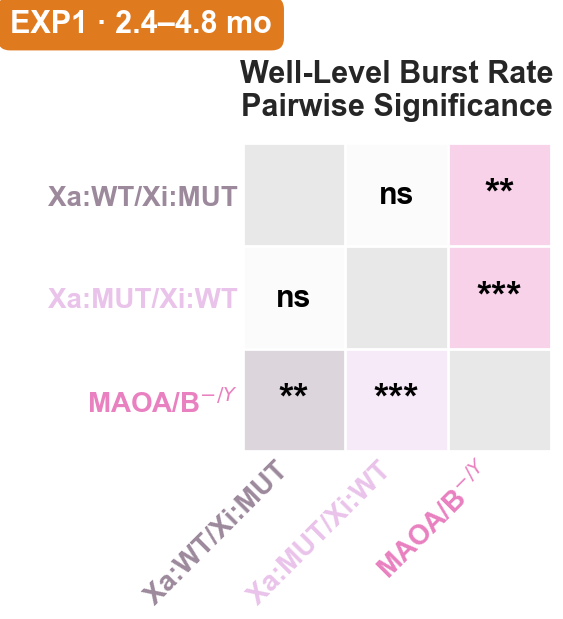

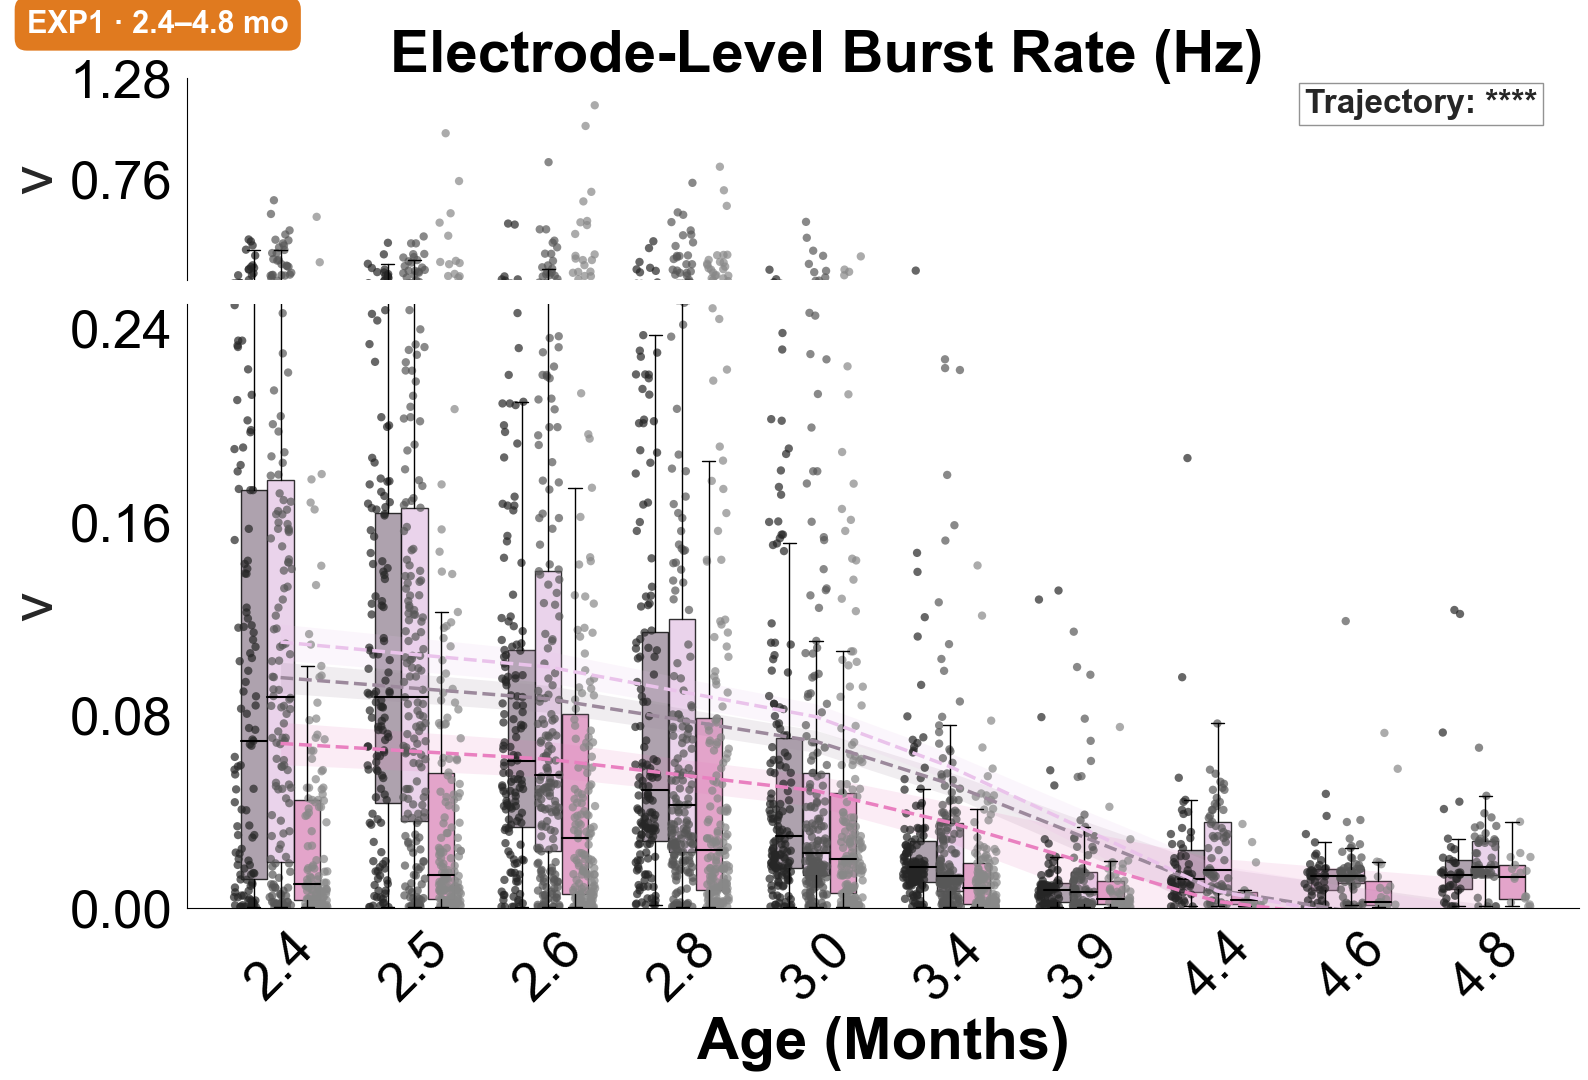

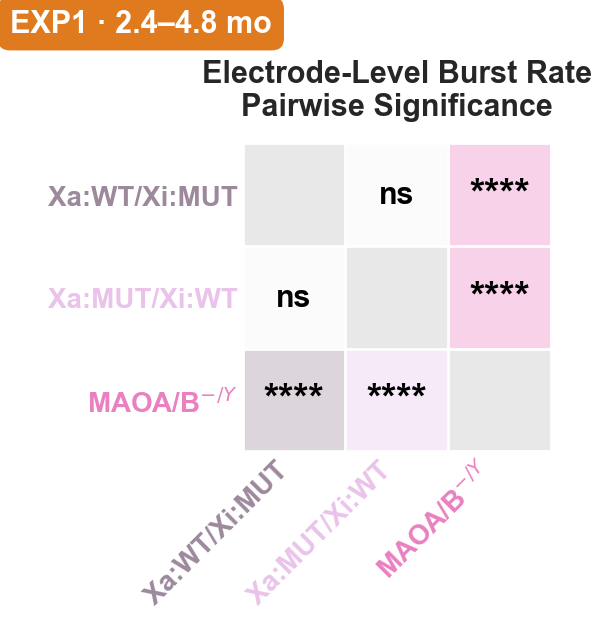


--- WELL-LEVEL BURST: mixed model, random intercept per well (n=192, wells=20) ---
       term        p  sig
      group  0.00232   **
        age 9.01e-48 ****
group x age 1.93e-05 ****
Overall group differences (Holm):
        group1       group2     diff    p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.0588 0.000694 ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.0507  0.00492  **
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.00803    0.655  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                           ****                           ****                           ns
  2.5                             **                              *                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                             ns                           ns
  3.0                             n


FEATURE: BURST


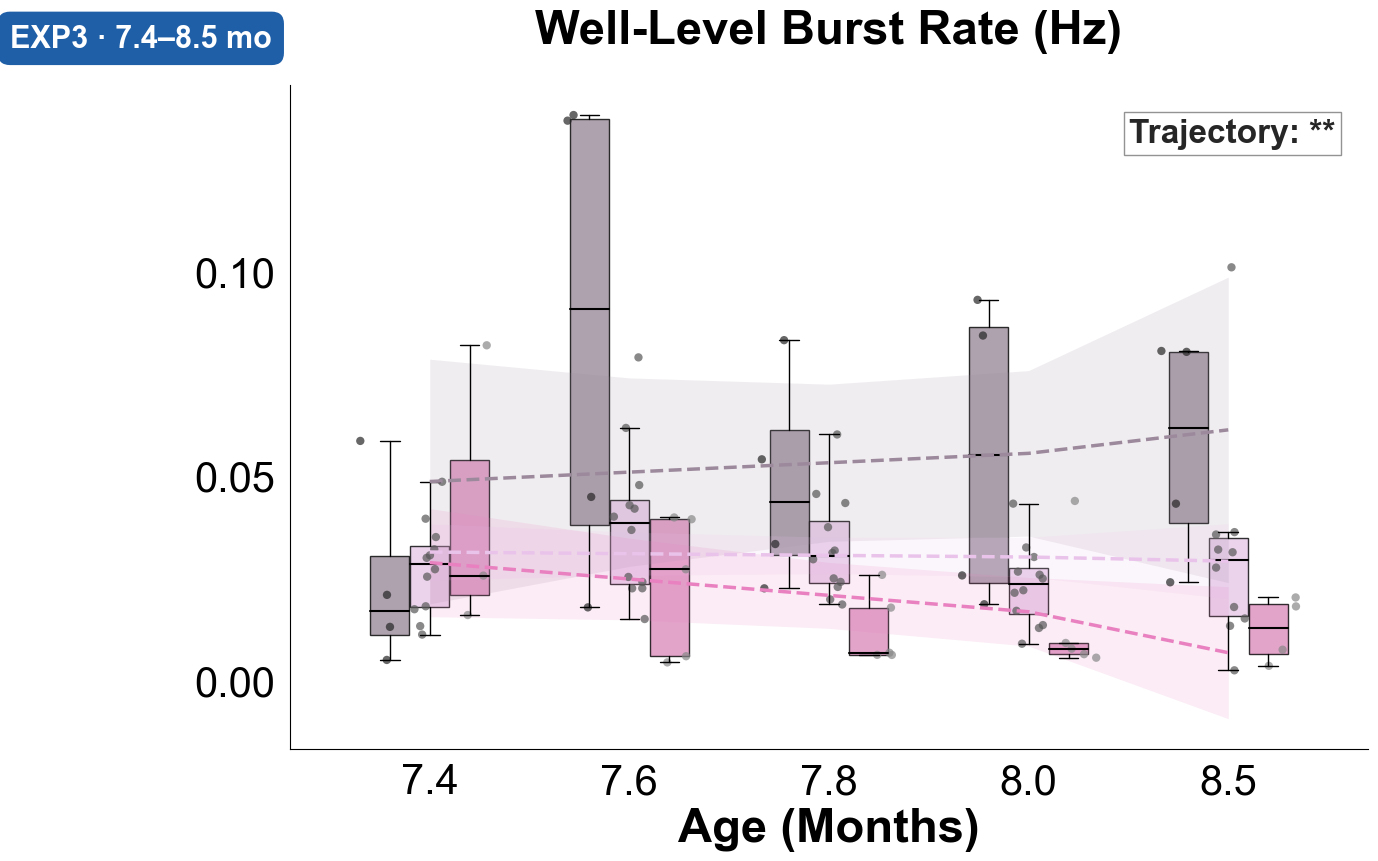

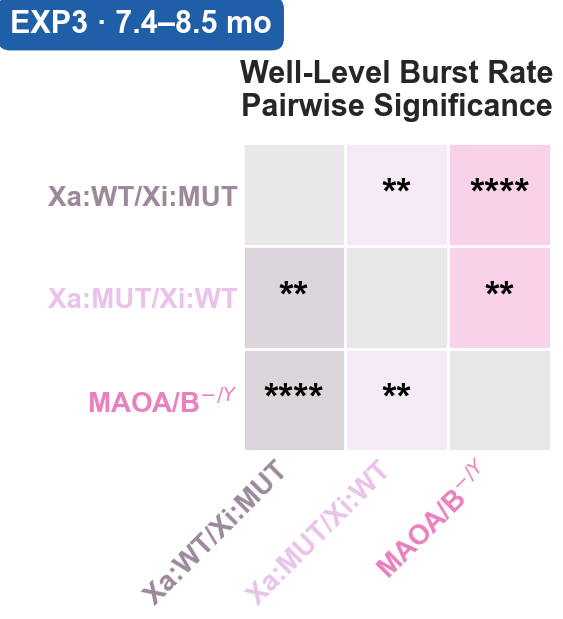

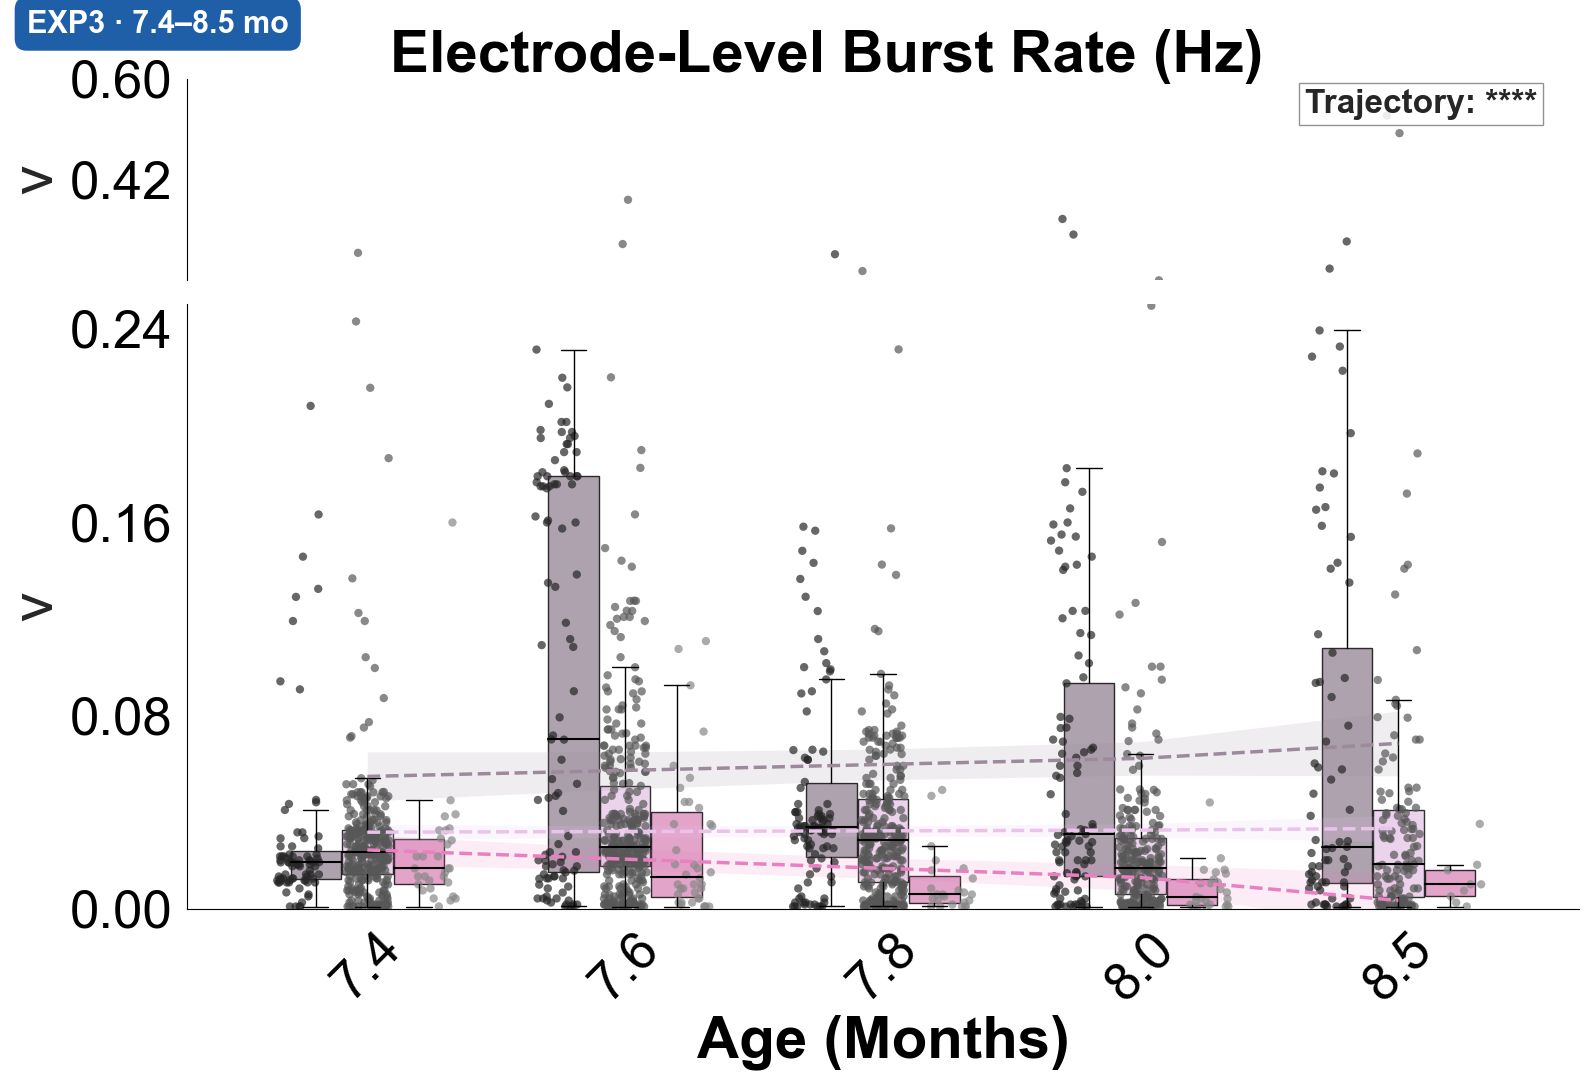

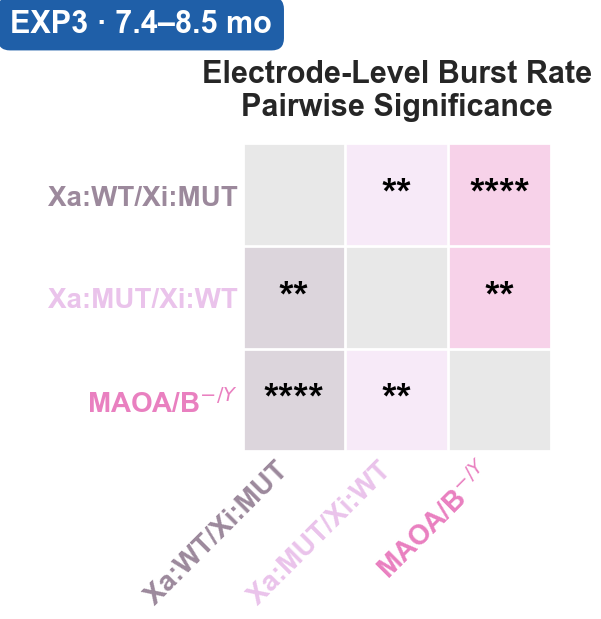


--- WELL-LEVEL BURST: mixed model, random intercept per well (n=100, wells=21) ---
       term        p  sig
      group 7.01e-05 ****
        age   0.0129    *
group x age  0.00317   **
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0409  0.00137   **
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.0873 9.23e-08 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0464  0.00105   **
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                             ns                           ****                           **
  7.8                              *                             **                           ns
  8.0                             ns                             **                            *
  8.5                             ns   

In [13]:
show_feature_by_experiment(datasets, "burst", "trajectory", palette=MAOA_FIGURE_PALETTE)

#### Overall group differences (all ages pooled)
Outputs per experiment: bar plot(s), then the "(BAR PLOT)" statistics block whose pairwise rows give the stars above the bars.


--- GENERATING GROUPED PLOTS FOR BURST ---


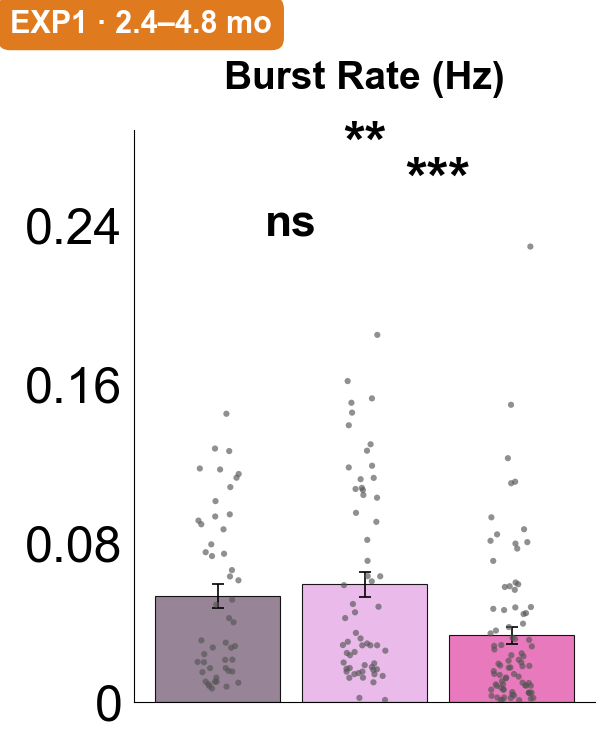

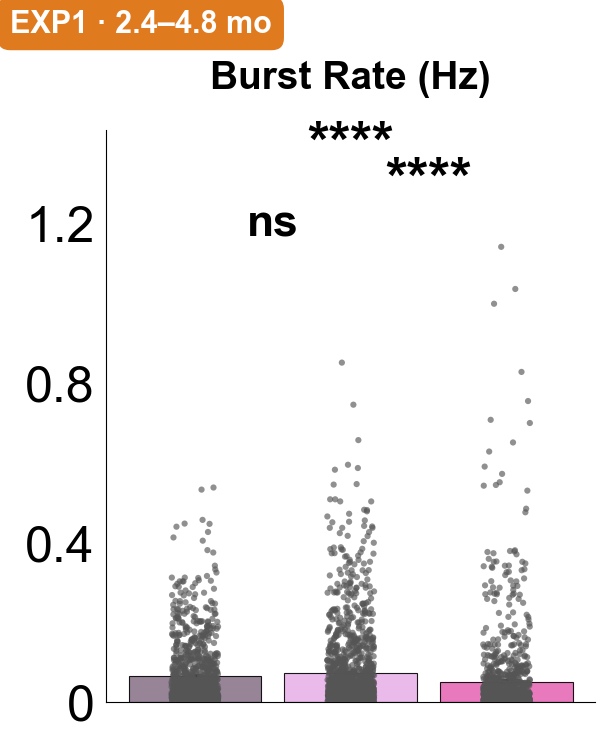


--- WELL-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=192, wells=20) ---
       term        p  sig
      group  0.00232   **
        age 9.01e-48 ****
group x age 1.93e-05 ****
Overall group differences (Holm):
        group1       group2     diff    p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.0588 0.000694 ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.0507  0.00492  **
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.00803    0.655  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                           ****                           ****                           ns
  2.5                             **                              *                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                             ns                           ns
  3.0                   


--- GENERATING GROUPED PLOTS FOR BURST ---


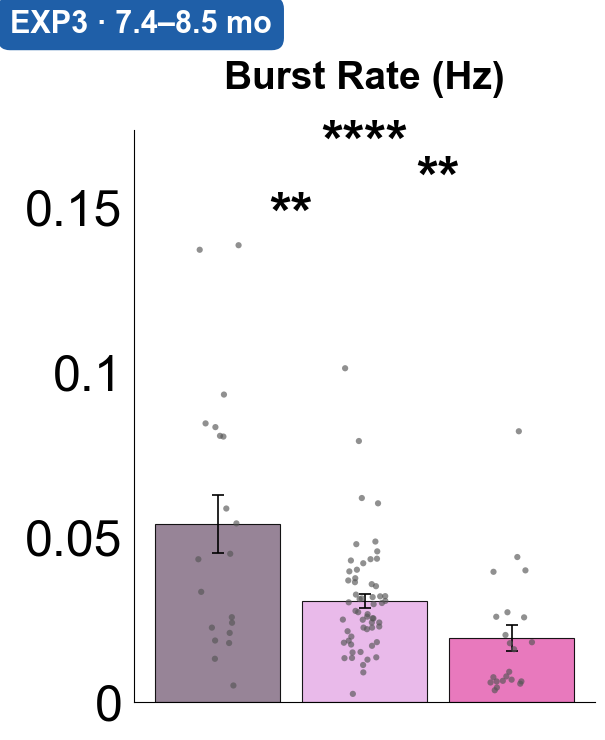

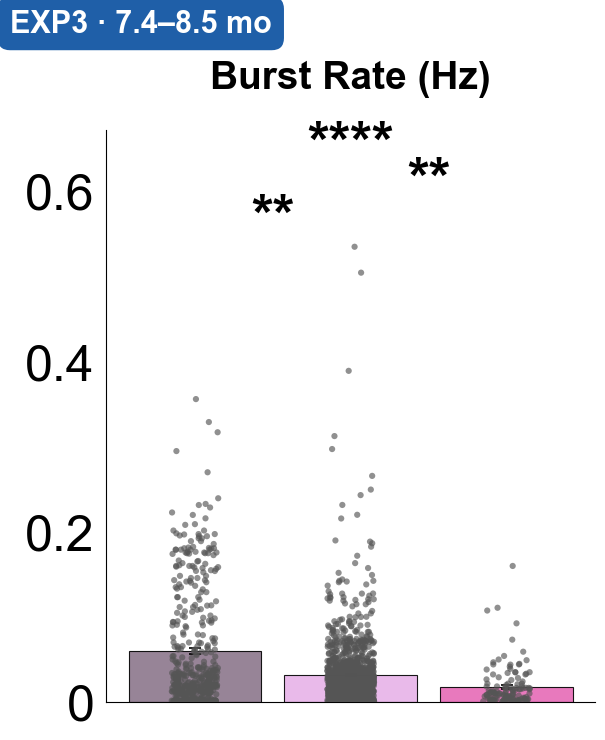


--- WELL-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=100, wells=21) ---
       term        p  sig
      group 7.01e-05 ****
        age   0.0129    *
group x age  0.00317   **
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0409  0.00137   **
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.0873 9.23e-08 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0464  0.00105   **
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                             ns                           ****                           **
  7.8                              *                             **                           ns
  8.0                             ns                             **                            *
  8.5                       

In [14]:
show_feature_by_experiment(datasets, "burst", "bars", palette=MAOA_FIGURE_PALETTE)

## 4.3 Network event rate
**What it measures:** network events per second. A network event is a run of ≥ 50 spikes across the well, with gaps ≤ 100 ms, involving ≥ 35 % of the well's active electrodes.

**What to look at:** well level only. Many wells have no network events at all, so expect many points at exactly 0 and boxes squashed onto the axis; the bar plot is often easier to read.

#### Trajectory across age
Outputs per experiment: trajectory plot(s) → significance matrix if the overall group effect is significant → printed statistics (group, age and group × age tests; overall pairs; per-age pairs).


FEATURE: NETWORK


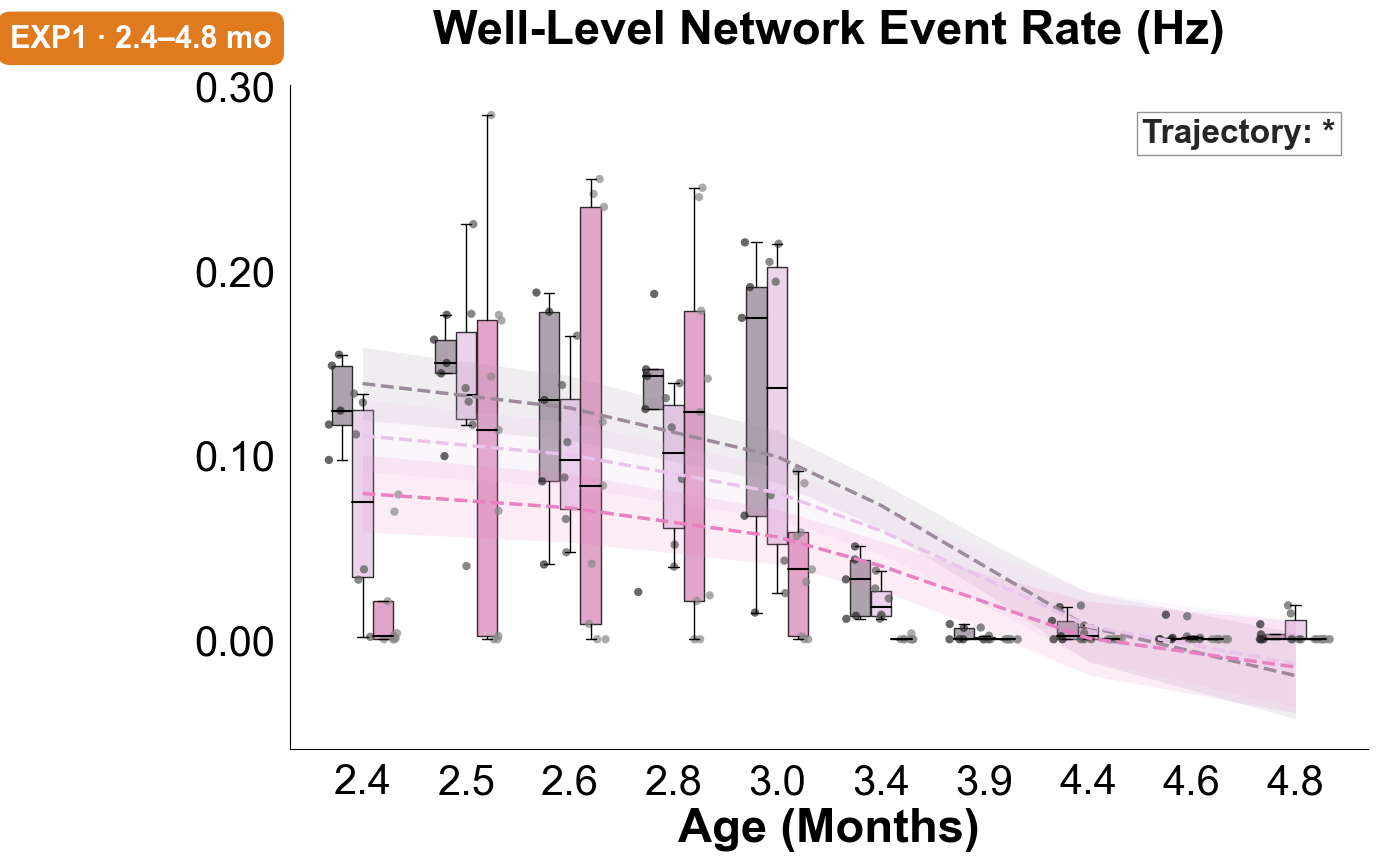

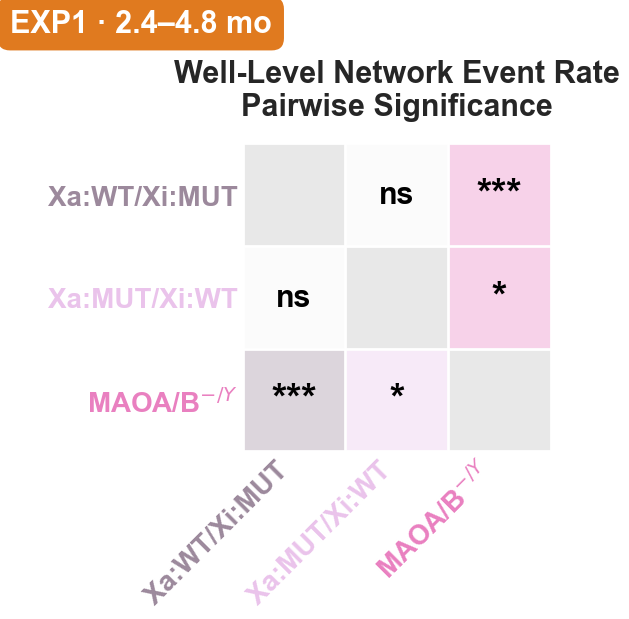


--- WELL-LEVEL NETWORK: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group  0.00332   **
        age 7.39e-41 ****
group x age   0.0369    *
Overall group differences (Holm):
        group1       group2   diff    p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0737   0.0111   *
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.101 0.000835 ***
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0276    0.359  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                              *                           ****                           ns
  2.5                             ns                             ns                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                             ns                           ns
  3.0                              *     


FEATURE: NETWORK


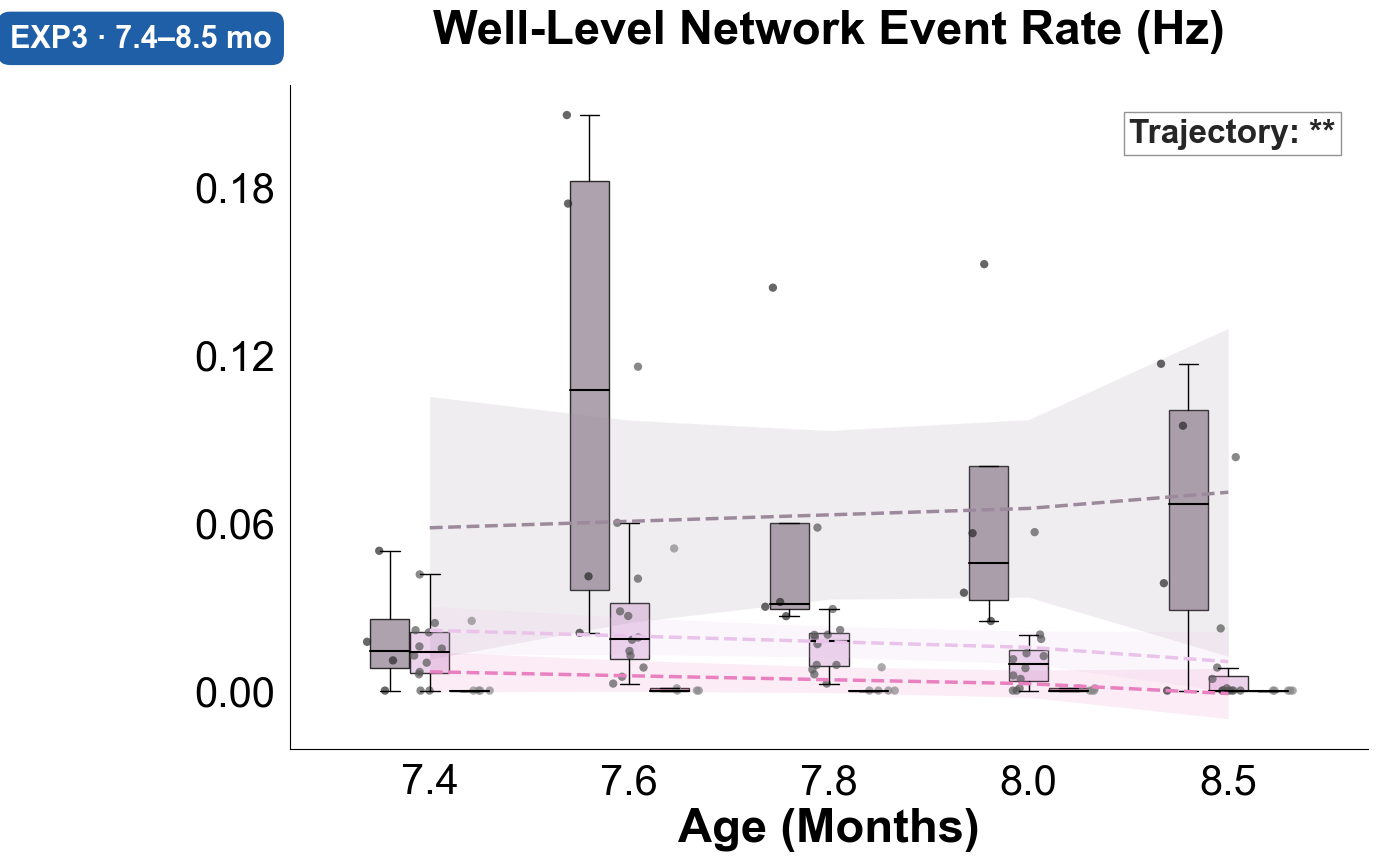

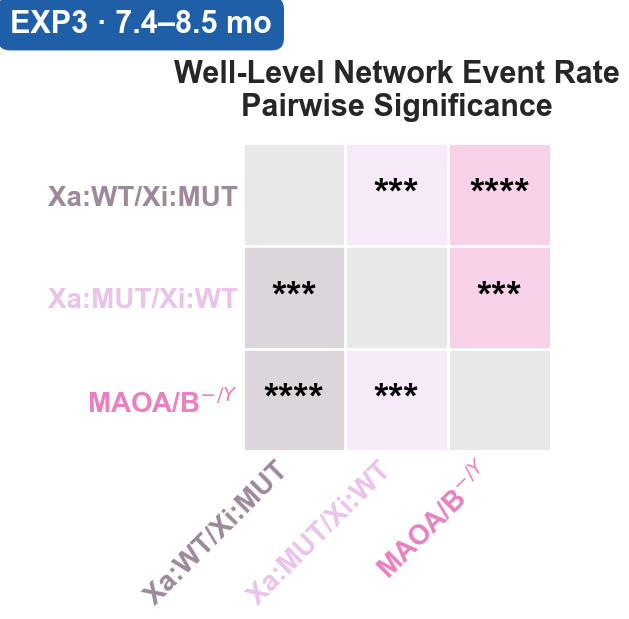


--- WELL-LEVEL NETWORK: mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 3.68e-05 ****
        age 7.97e-05 ****
group x age   0.0095   **
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0837 0.000935  ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.187 1.26e-08 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT  0.103 0.000341  ***
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                              *                           ****                           **
  7.8                              *                            ***                           ns
  8.0                             ns                           ****                           **
  8.5                             ns 

In [15]:
show_feature_by_experiment(datasets, "network", "trajectory", palette=MAOA_FIGURE_PALETTE)

#### Overall group differences (all ages pooled)
Outputs per experiment: bar plot(s), then the "(BAR PLOT)" statistics block whose pairwise rows give the stars above the bars.


--- GENERATING GROUPED PLOTS FOR NETWORK ---


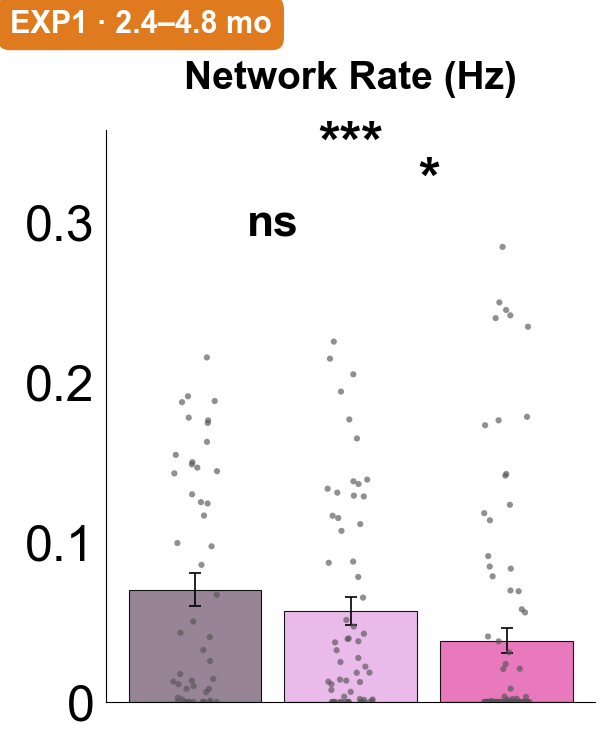


--- WELL-LEVEL NETWORK (BAR PLOT): mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group  0.00332   **
        age 7.39e-41 ****
group x age   0.0369    *
Overall group differences (Holm):
        group1       group2   diff    p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0737   0.0111   *
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.101 0.000835 ***
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0276    0.359  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                              *                           ****                           ns
  2.5                             ns                             ns                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                             ns                           ns
  3.0                         


--- GENERATING GROUPED PLOTS FOR NETWORK ---


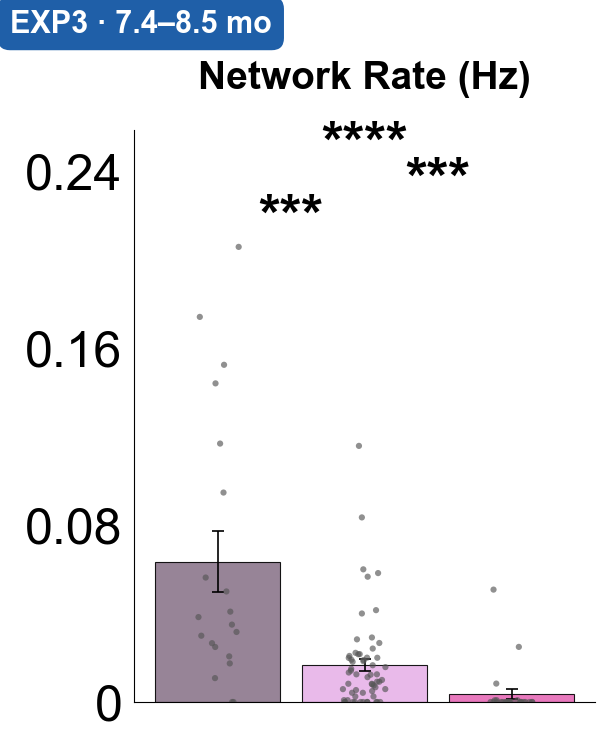


--- WELL-LEVEL NETWORK (BAR PLOT): mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 3.68e-05 ****
        age 7.97e-05 ****
group x age   0.0095   **
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0837 0.000935  ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.187 1.26e-08 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT  0.103 0.000341  ***
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                              *                           ****                           **
  7.8                              *                            ***                           ns
  8.0                             ns                           ****                           **
  8.5                     

In [16]:
show_feature_by_experiment(datasets, "network", "bars", palette=MAOA_FIGURE_PALETTE)

## 4.4 Synchrony index
**What it measures:** how strongly electrodes fire together: the mean correlation between all pairs of electrodes (spike counts in 20 ms bins). 0 = independent firing, 1 = identical firing; slightly negative values are noise around 0.

**What to look at:** well level only, unitless. Wells with fewer than two electrodes with ≥ 10 spikes have no value and are left out. Synchrony is analysed untransformed, so "diff" in the printed stats is directly in index units.

#### Trajectory across age
Outputs per experiment: trajectory plot(s) → significance matrix if the overall group effect is significant → printed statistics (group, age and group × age tests; overall pairs; per-age pairs).


FEATURE: SYNCHRONY


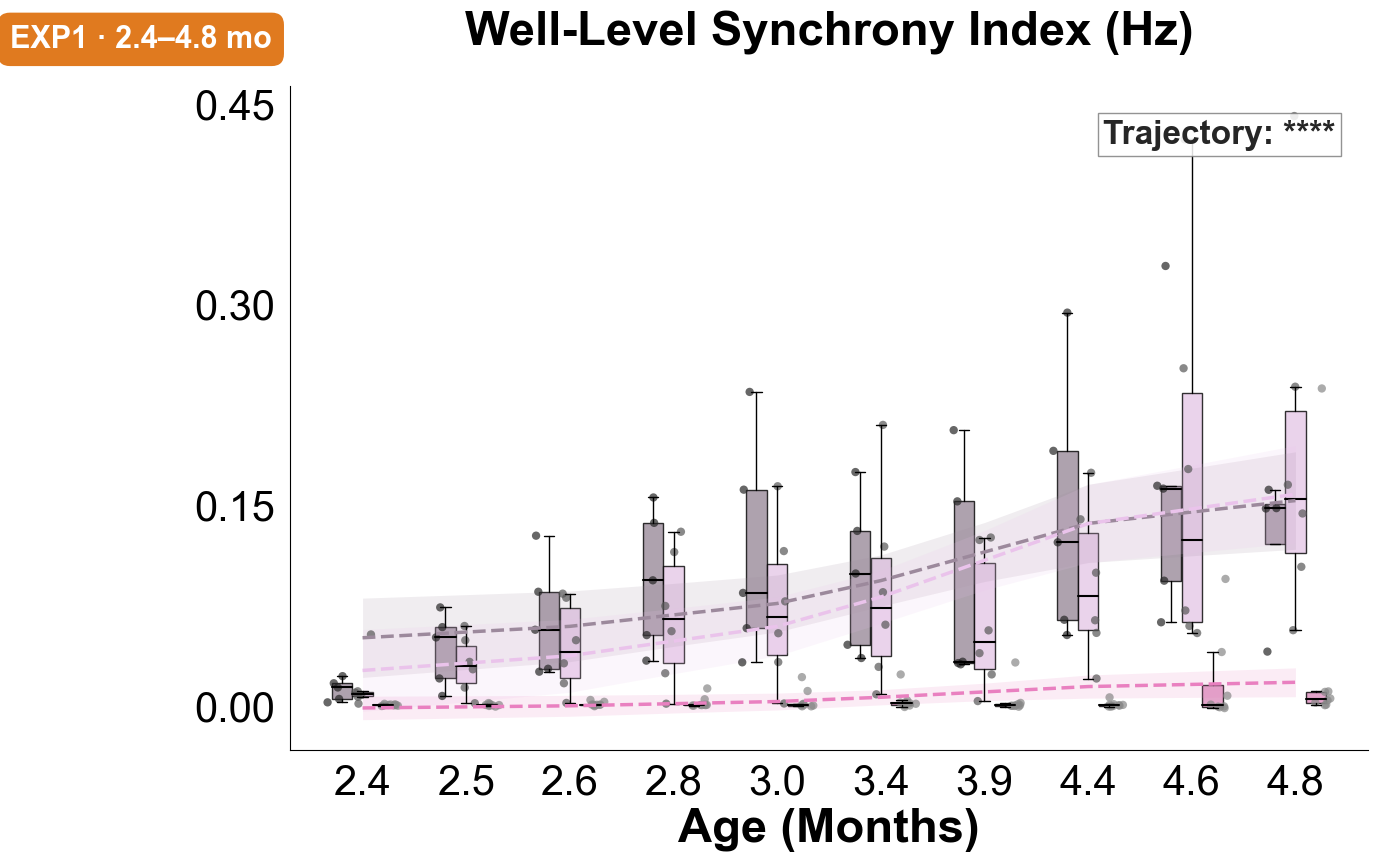

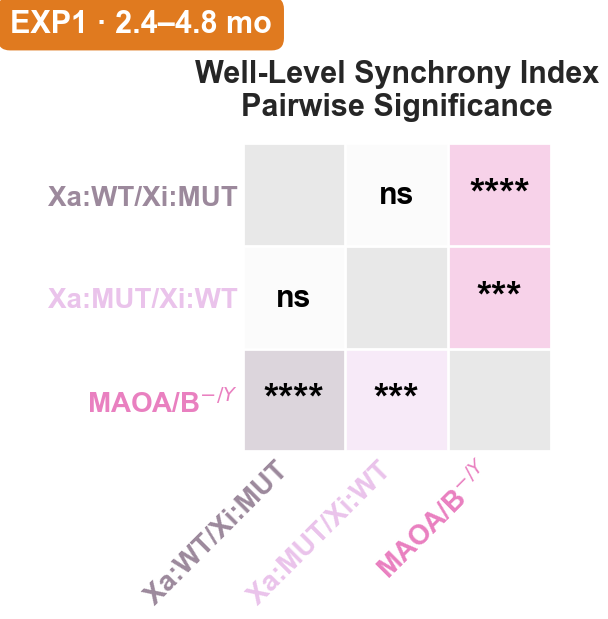


--- WELL-LEVEL SYNCHRONY: mixed model, random intercept per well (n=197, wells=20) ---
       term        p  sig
      group 0.000488  ***
        age 1.54e-12 ****
group x age 1.05e-06 ****
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0716 0.000479  ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.0868 6.68e-05 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0152    0.491   ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                             ns                             ns                           ns
  2.5                             ns                             ns                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                              *                           ns
  3.0                             n


FEATURE: SYNCHRONY


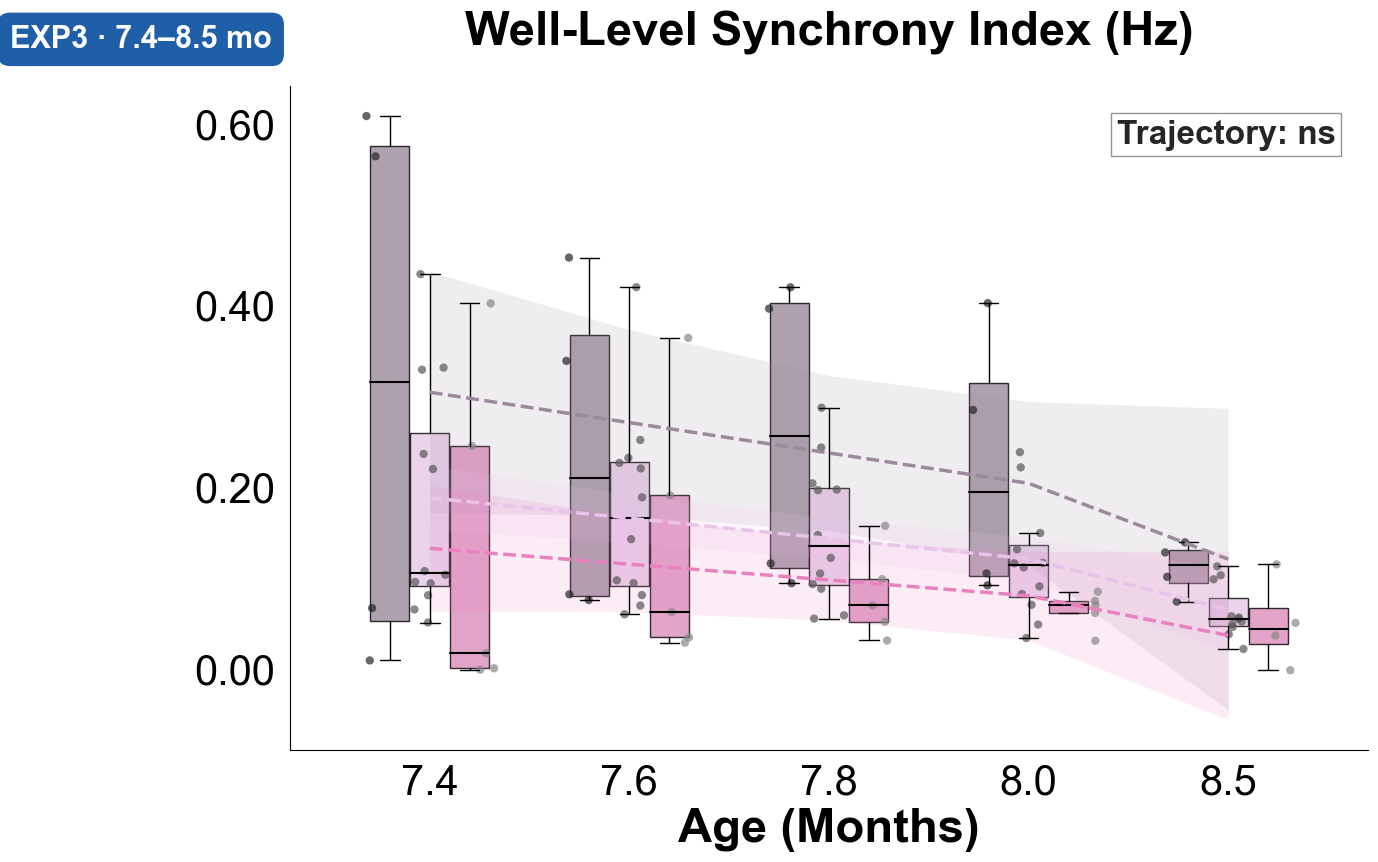

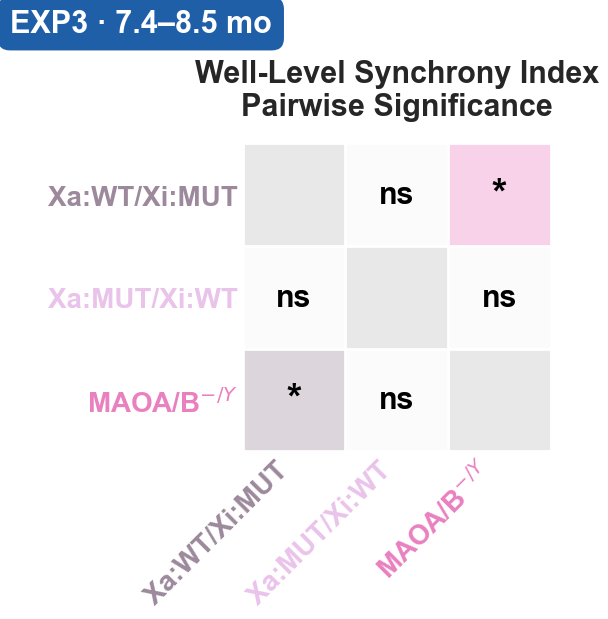


--- WELL-LEVEL SYNCHRONY: mixed model, random intercept per well (n=103, wells=21) ---
       term        p  sig
      group   0.0466    *
        age 9.83e-06 ****
group x age    0.843   ns
Overall group differences (Holm):
        group1       group2   diff  p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0592  0.172  ns
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.133 0.0229   *
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0737  0.172  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                             ns                             ns                           ns
  7.8                             ns                             ns                           ns
  8.0                             ns                             ns                           ns
  8.5                             ns           

In [17]:
show_feature_by_experiment(datasets, "synchrony", "trajectory", palette=MAOA_FIGURE_PALETTE)

#### Overall group differences (all ages pooled)
Outputs per experiment: bar plot(s), then the "(BAR PLOT)" statistics block whose pairwise rows give the stars above the bars.


--- GENERATING GROUPED PLOTS FOR SYNCHRONY ---


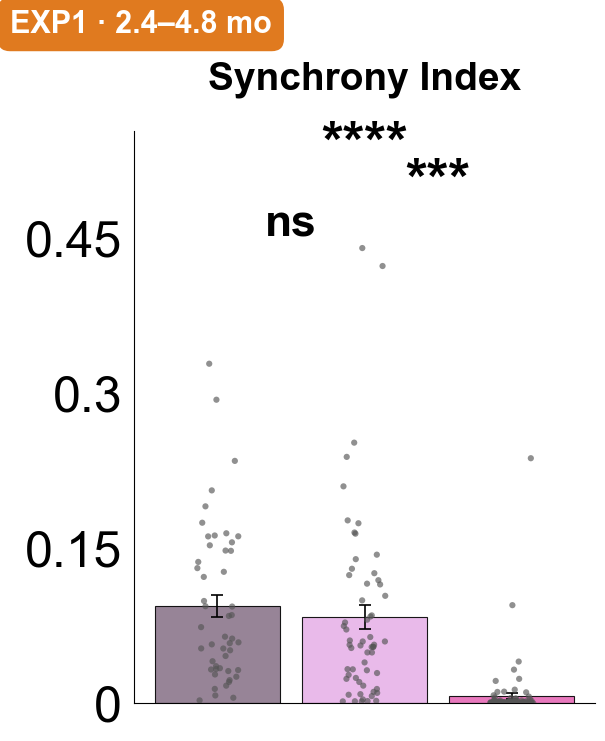


--- WELL-LEVEL SYNCHRONY (BAR PLOT): mixed model, random intercept per well (n=197, wells=20) ---
       term        p  sig
      group 0.000488  ***
        age 1.54e-12 ****
group x age 1.05e-06 ****
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0716 0.000479  ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.0868 6.68e-05 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0152    0.491   ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                             ns                             ns                           ns
  2.5                             ns                             ns                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                              *                           ns
  3.0                   


--- GENERATING GROUPED PLOTS FOR SYNCHRONY ---


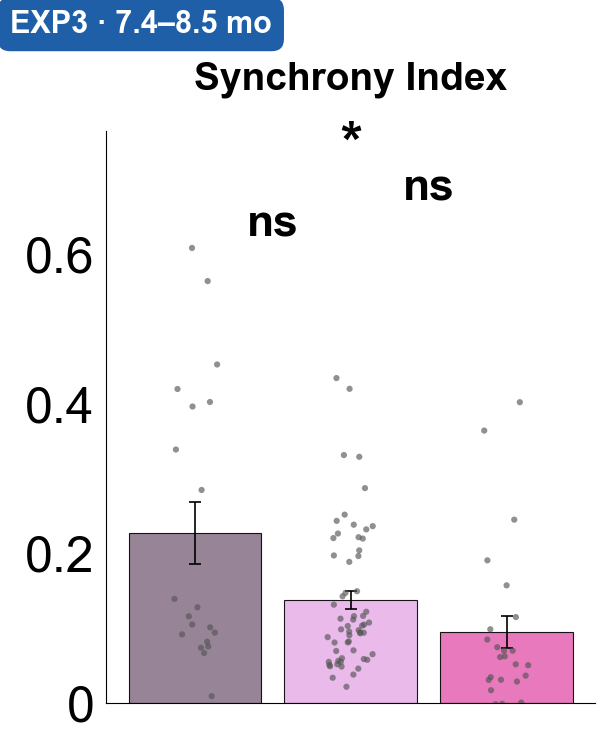


--- WELL-LEVEL SYNCHRONY (BAR PLOT): mixed model, random intercept per well (n=103, wells=21) ---
       term        p  sig
      group   0.0466    *
        age 9.83e-06 ****
group x age    0.843   ns
Overall group differences (Holm):
        group1       group2   diff  p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0592  0.172  ns
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.133 0.0229   *
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0737  0.172  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  7.4                             ns                             ns                           ns
  7.6                             ns                             ns                           ns
  7.8                             ns                             ns                           ns
  8.0                             ns                             ns                           ns
  8.5                             ns

In [18]:
show_feature_by_experiment(datasets, "synchrony", "bars", palette=MAOA_FIGURE_PALETTE)

---
# 5. Supplementary — each clone separately
The same plots and statistics with every clone as its own group: C30 (Xa:WT/Xi:MUT), C71 and C3 (both Xa:MUT/Xi:WT) and GM (KO).
Read them exactly as in section 4. The difference is that the pairwise tests compare clones (six pairs, Holm-corrected over six),
so you can see whether a genotype difference holds for each clone or is carried by one.
In Exp1 C3 comes from one well per day only (MAOA1), so its boxes and estimates are noisy.

## 5.1 Firing rate by clone


FEATURE: FIRING


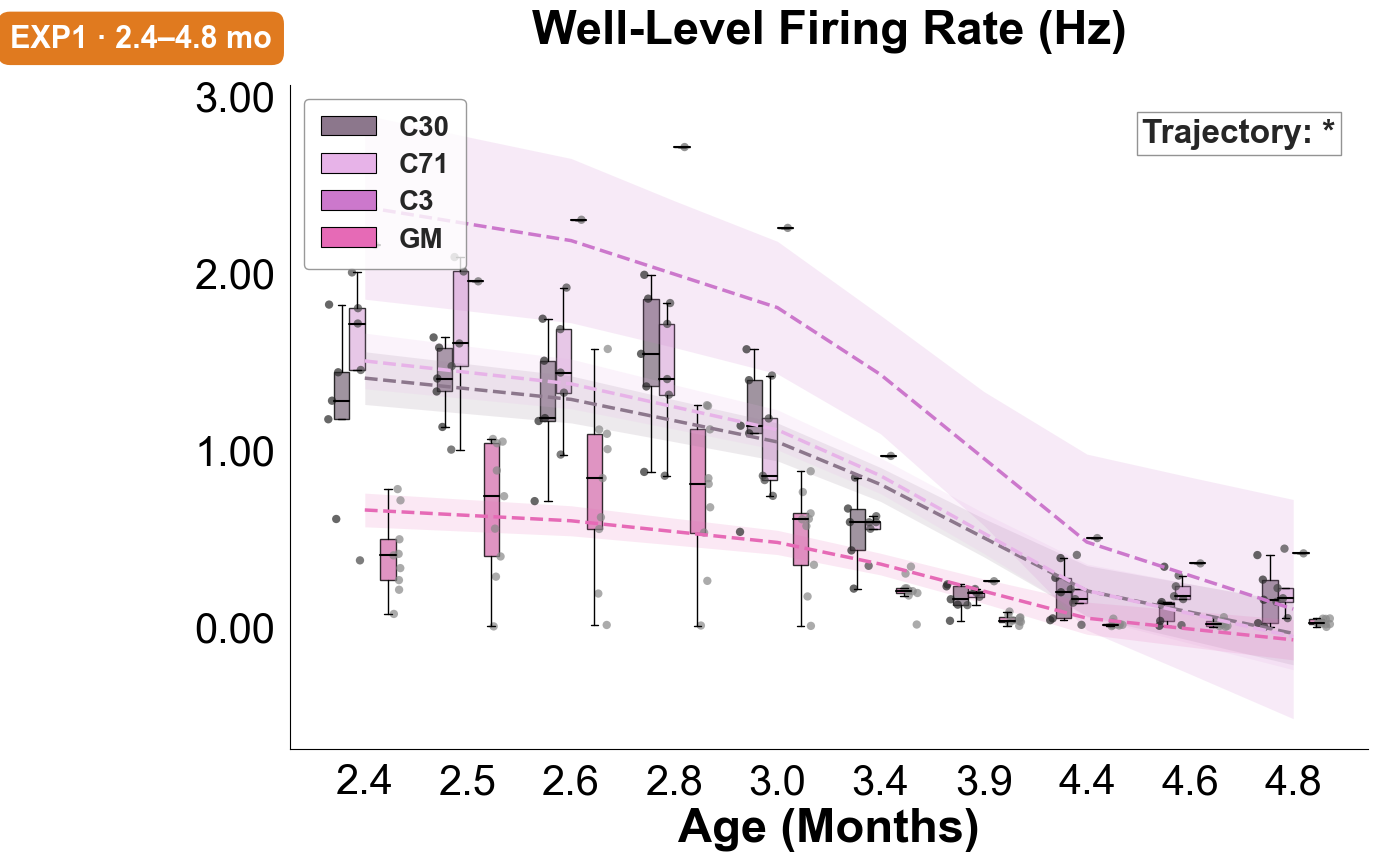

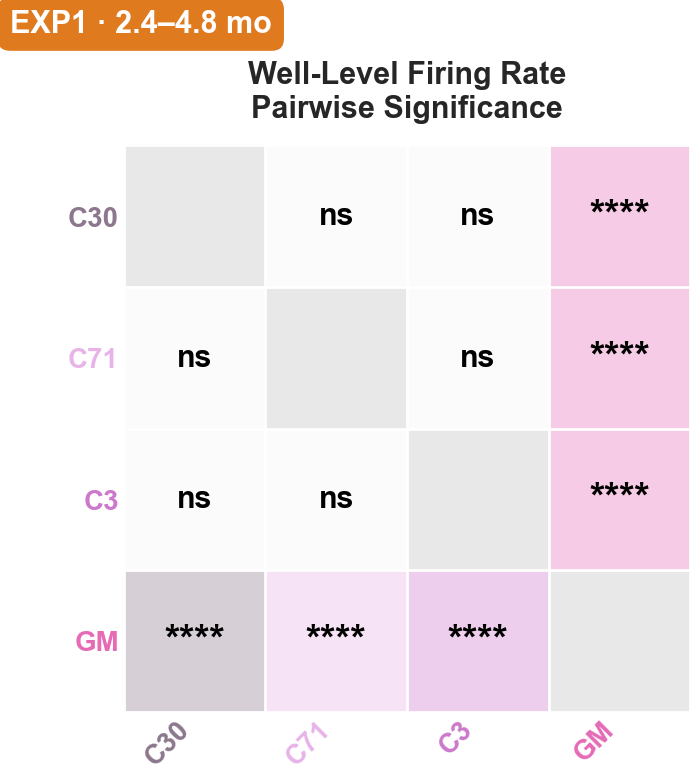

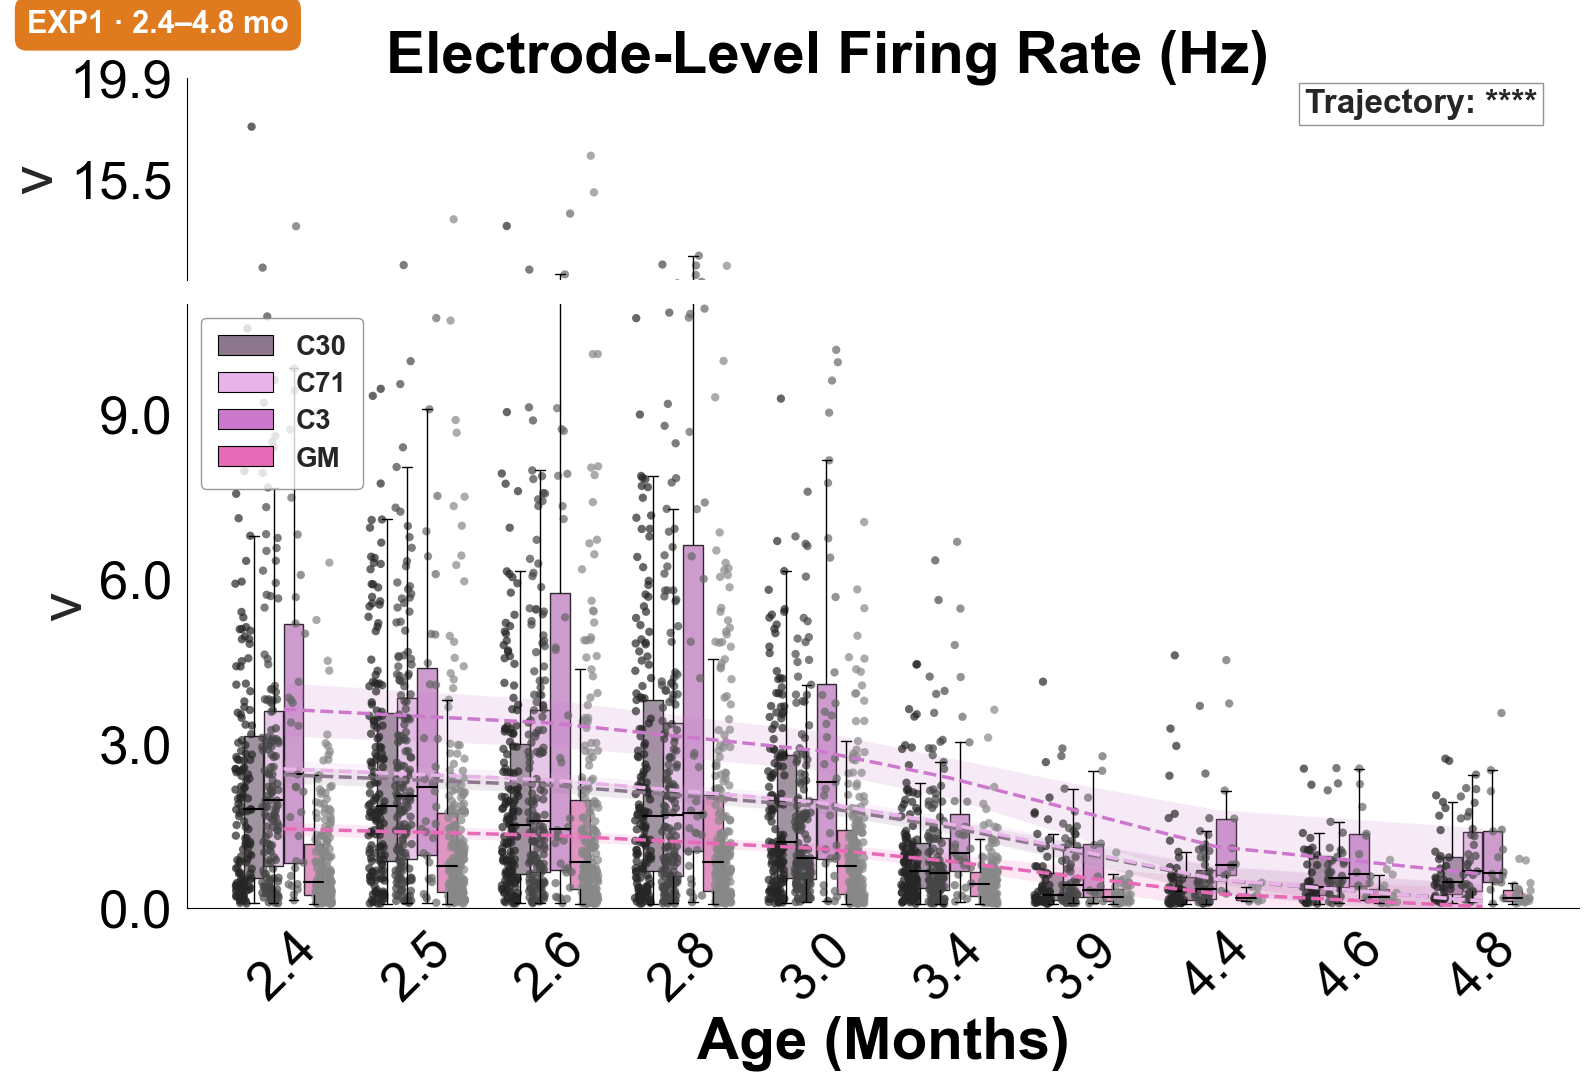

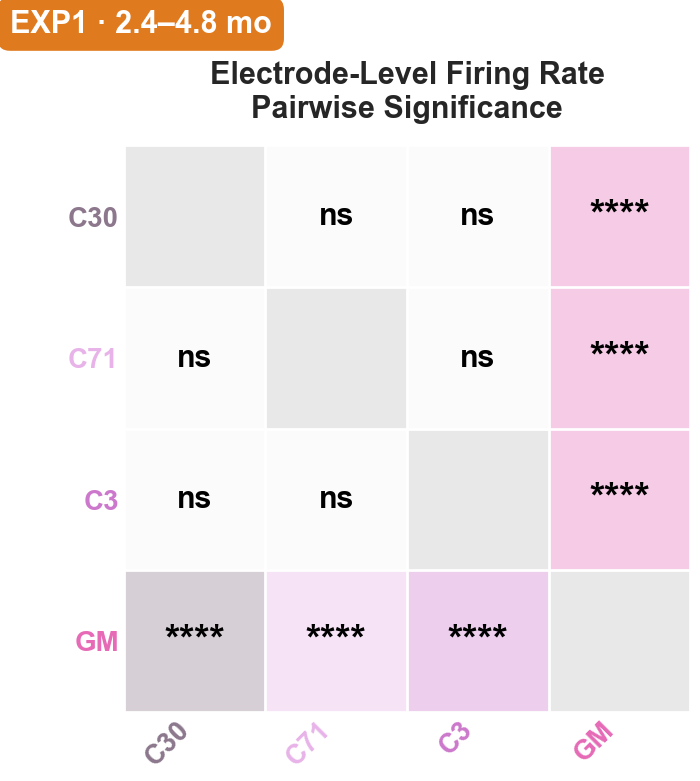


--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.72e-05 ****
        age 1.68e-70 ****
group x age   0.0322    *
Overall group differences (Holm):
group1 group2   diff    p-adj  sig
    C3    C30 -0.262    0.156   ns
    C3    C71 -0.229    0.181   ns
    C3     GM -0.558 8.55e-05 ****
   C30    C71 0.0336    0.656   ns
   C30     GM -0.296 5.04e-05 ****
   C71     GM -0.329 5.28e-06 ****
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns      ***         ns      ****      ****
  2.5        ns        ns       ns         ns       ***      ****
  2.6        ns        ns        *         ns        ns        **
  2.8        ns        ns       **         ns        **        **
  3.0        ns        ns       **         ns        **        ns
  3.4        ns        ns       ns         ns        ns        ns
  3.9       


FEATURE: FIRING


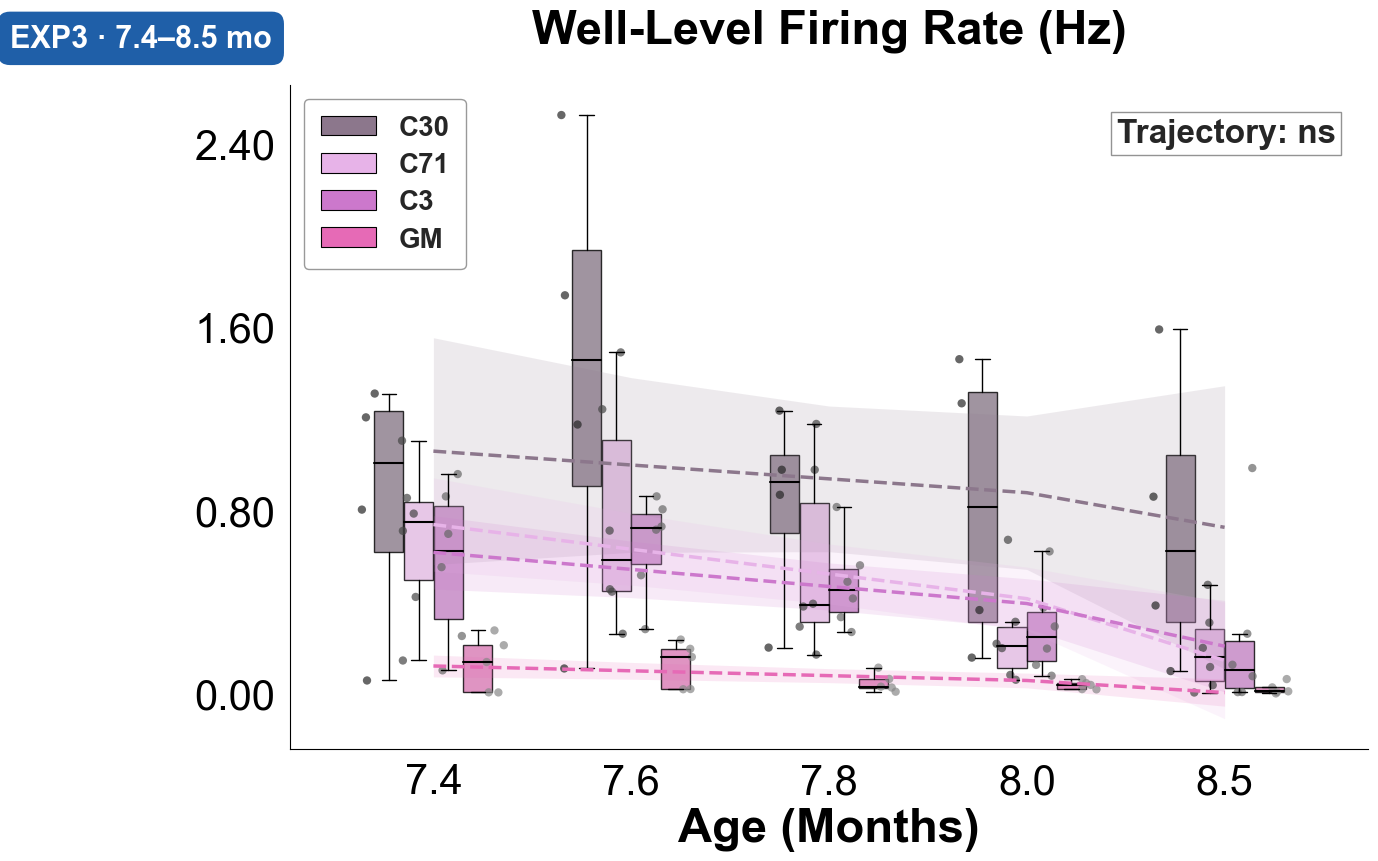

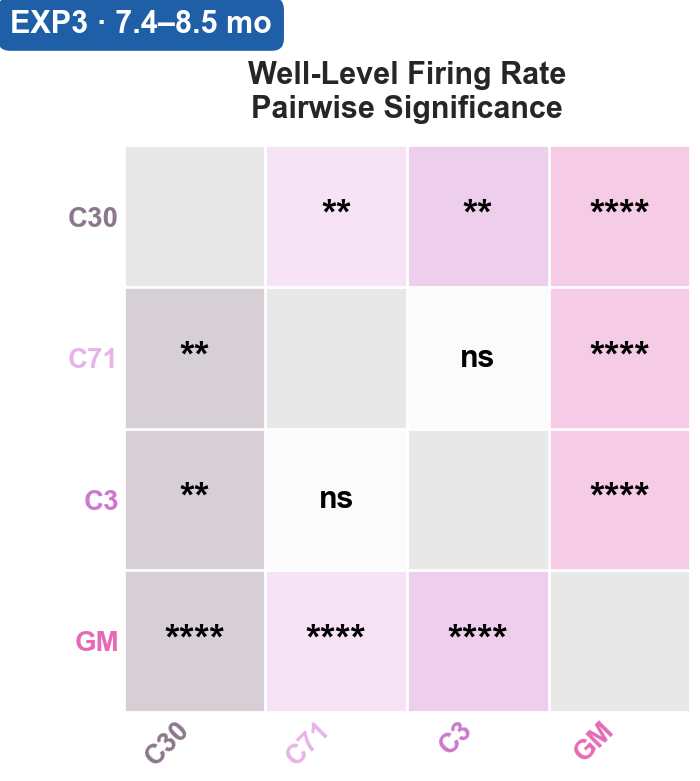

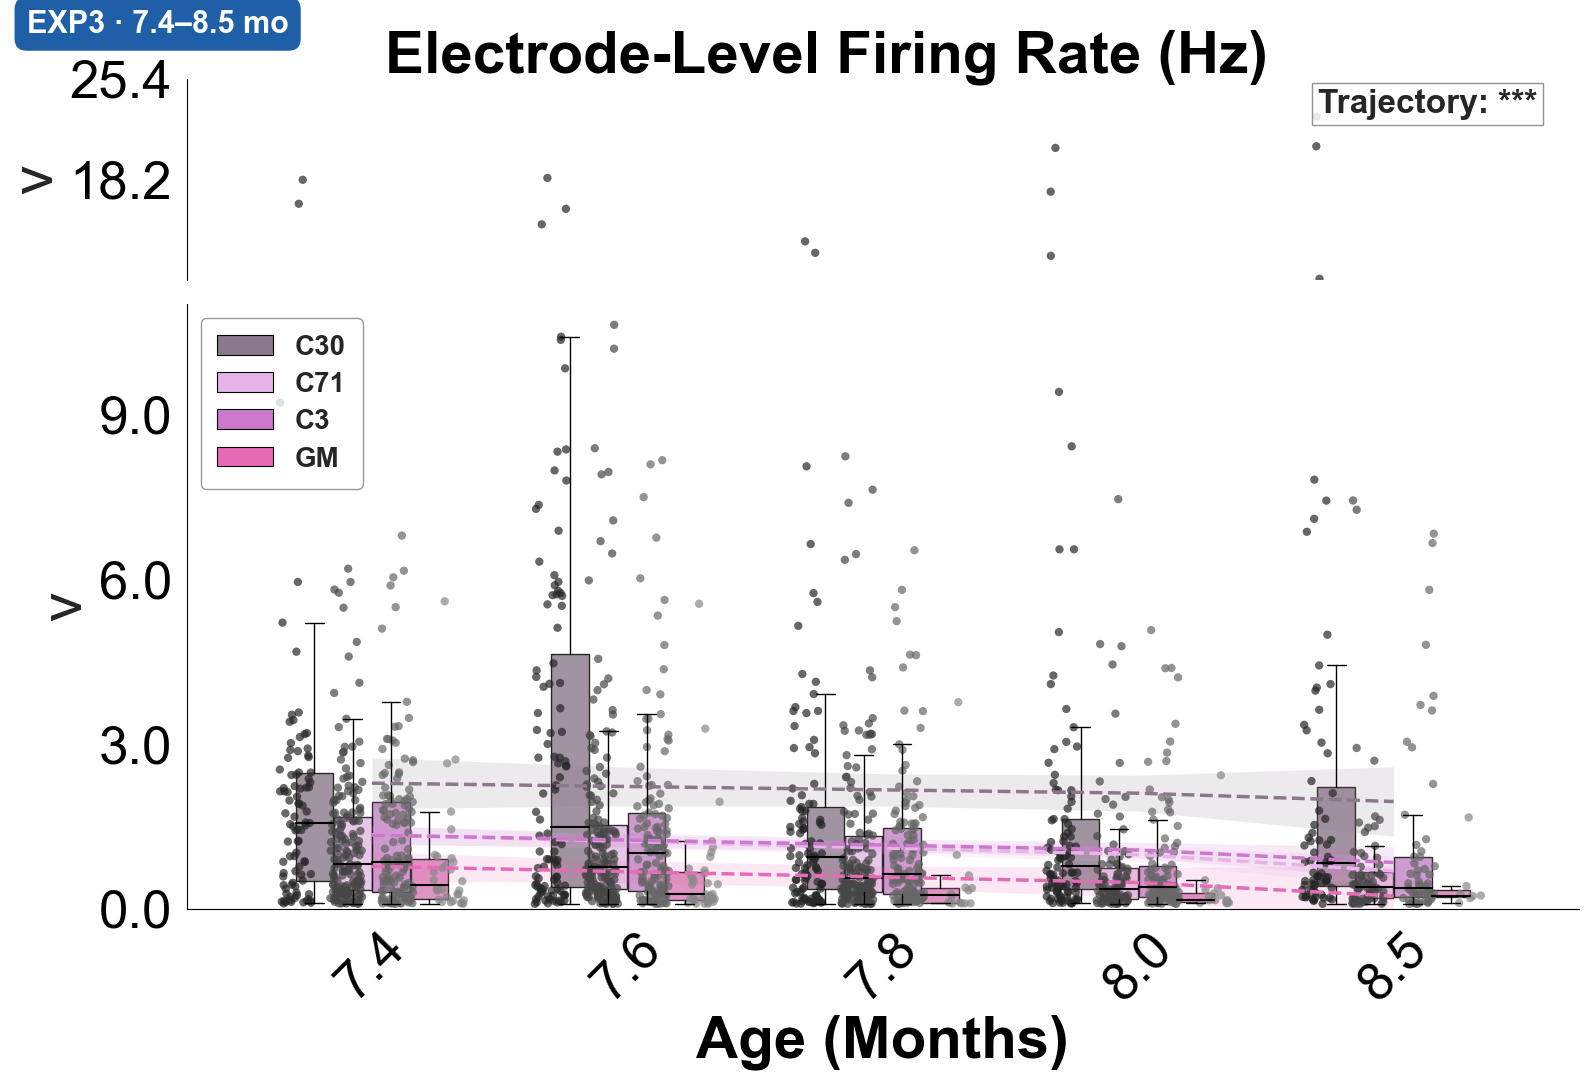

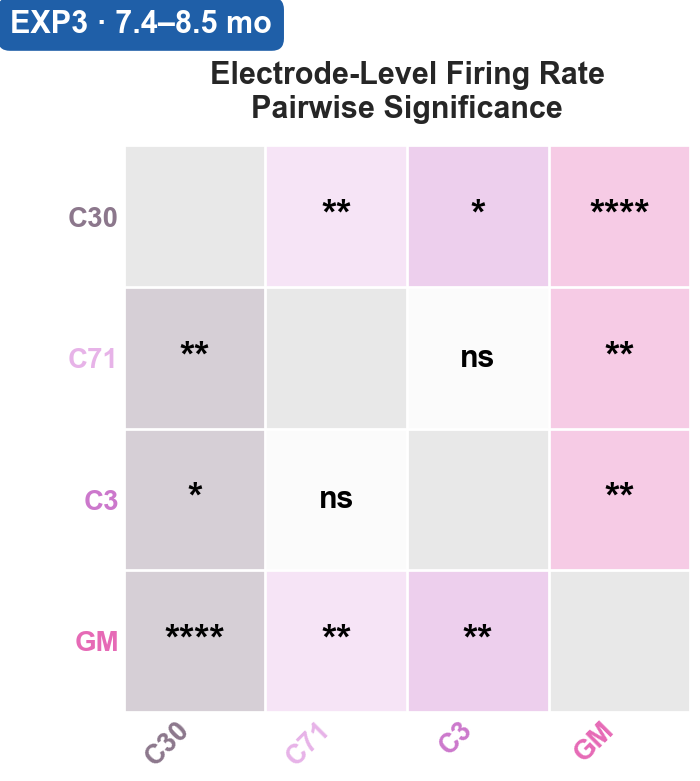


--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 3.61e-06 ****
        age 2.04e-12 ****
group x age   0.0691   ns
Overall group differences (Holm):
group1 group2   diff    p-adj  sig
    C3    C30  0.243  0.00543   **
    C3    C71 0.0221    0.749   ns
    C3     GM -0.356  4.2e-06 ****
   C30    C71 -0.221  0.00914   **
   C30     GM -0.599 7.33e-13 ****
   C71     GM -0.379 1.08e-06 ****
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       **         ns       ***      ****
  7.6        ns        ns      ***         ns      ****      ****
  7.8        ns        ns      ***         ns      ****      ****
  8.0        ns        ns       ns          *      ****        ns
  8.5        **        ns       ns         **      ****        ns

--- ELECTRODE-LEVEL FIRING: mixed model, random intercept per well + per elec

In [19]:
show_feature_by_experiment(datasets, "firing", "clone_trajectory", palette=MAOA_FIGURE_PALETTE)


--- GENERATING CLONE PLOTS FOR FIRING ---


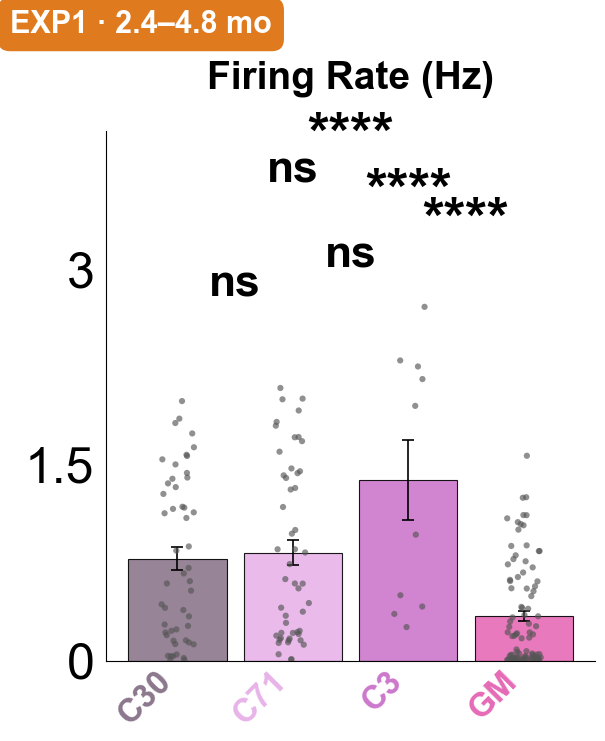

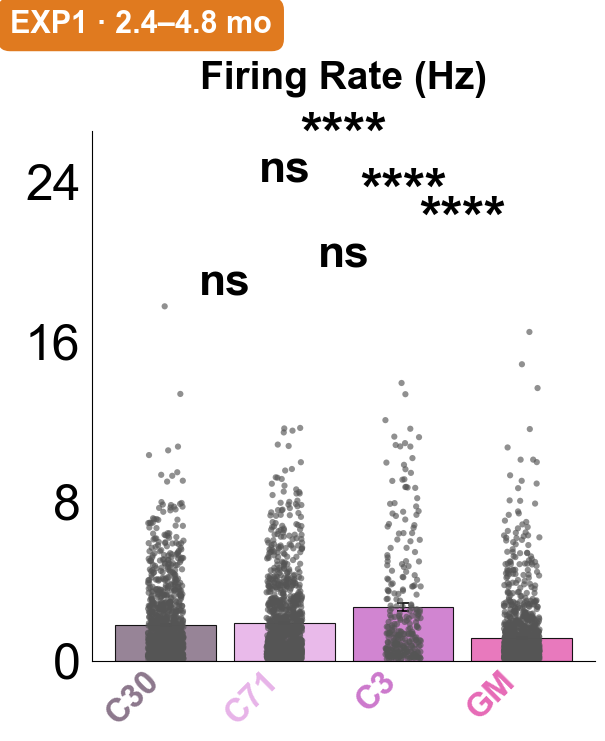


--- WELL-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.72e-05 ****
        age 1.68e-70 ****
group x age   0.0322    *
Overall group differences (Holm):
group1 group2   diff    p-adj  sig
    C3    C30 -0.262    0.156   ns
    C3    C71 -0.229    0.181   ns
    C3     GM -0.558 8.55e-05 ****
   C30    C71 0.0336    0.656   ns
   C30     GM -0.296 5.04e-05 ****
   C71     GM -0.329 5.28e-06 ****
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns      ***         ns      ****      ****
  2.5        ns        ns       ns         ns       ***      ****
  2.6        ns        ns        *         ns        ns        **
  2.8        ns        ns       **         ns        **        **
  3.0        ns        ns       **         ns        **        ns
  3.4        ns        ns       ns         ns        ns        ns
 


--- GENERATING CLONE PLOTS FOR FIRING ---


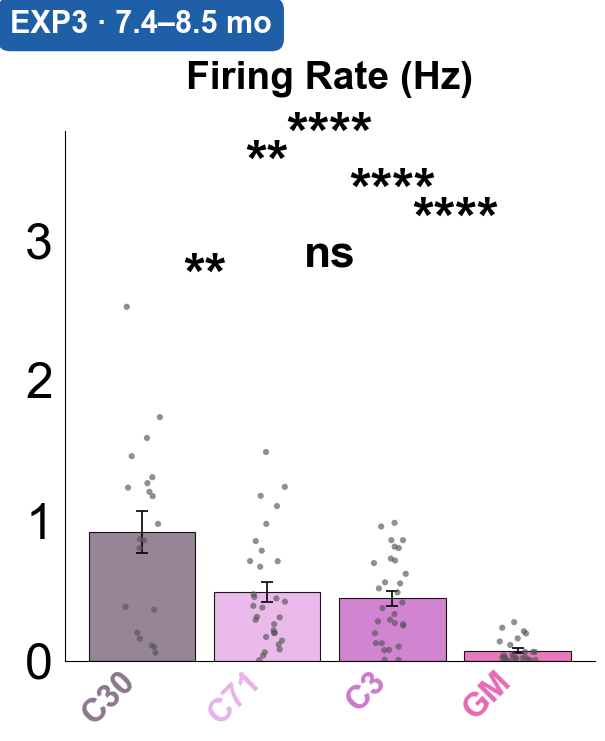

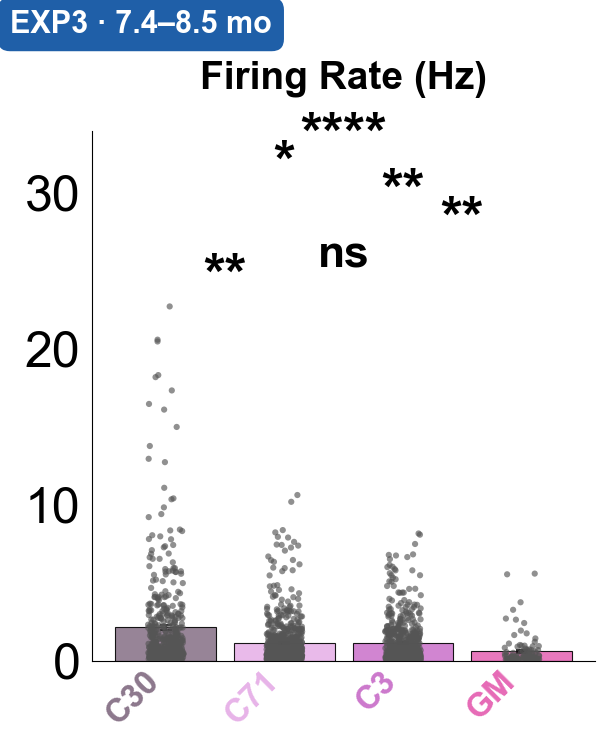


--- WELL-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 3.61e-06 ****
        age 2.04e-12 ****
group x age   0.0691   ns
Overall group differences (Holm):
group1 group2   diff    p-adj  sig
    C3    C30  0.243  0.00543   **
    C3    C71 0.0221    0.749   ns
    C3     GM -0.356  4.2e-06 ****
   C30    C71 -0.221  0.00914   **
   C30     GM -0.599 7.33e-13 ****
   C71     GM -0.379 1.08e-06 ****
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       **         ns       ***      ****
  7.6        ns        ns      ***         ns      ****      ****
  7.8        ns        ns      ***         ns      ****      ****
  8.0        ns        ns       ns          *      ****        ns
  8.5        **        ns       ns         **      ****        ns

--- ELECTRODE-LEVEL FIRING (BAR PLOT): mixed model, random interce

In [20]:
show_feature_by_experiment(datasets, "firing", "clone_bars", palette=MAOA_FIGURE_PALETTE)

## 5.2 Burst rate by clone


FEATURE: BURST


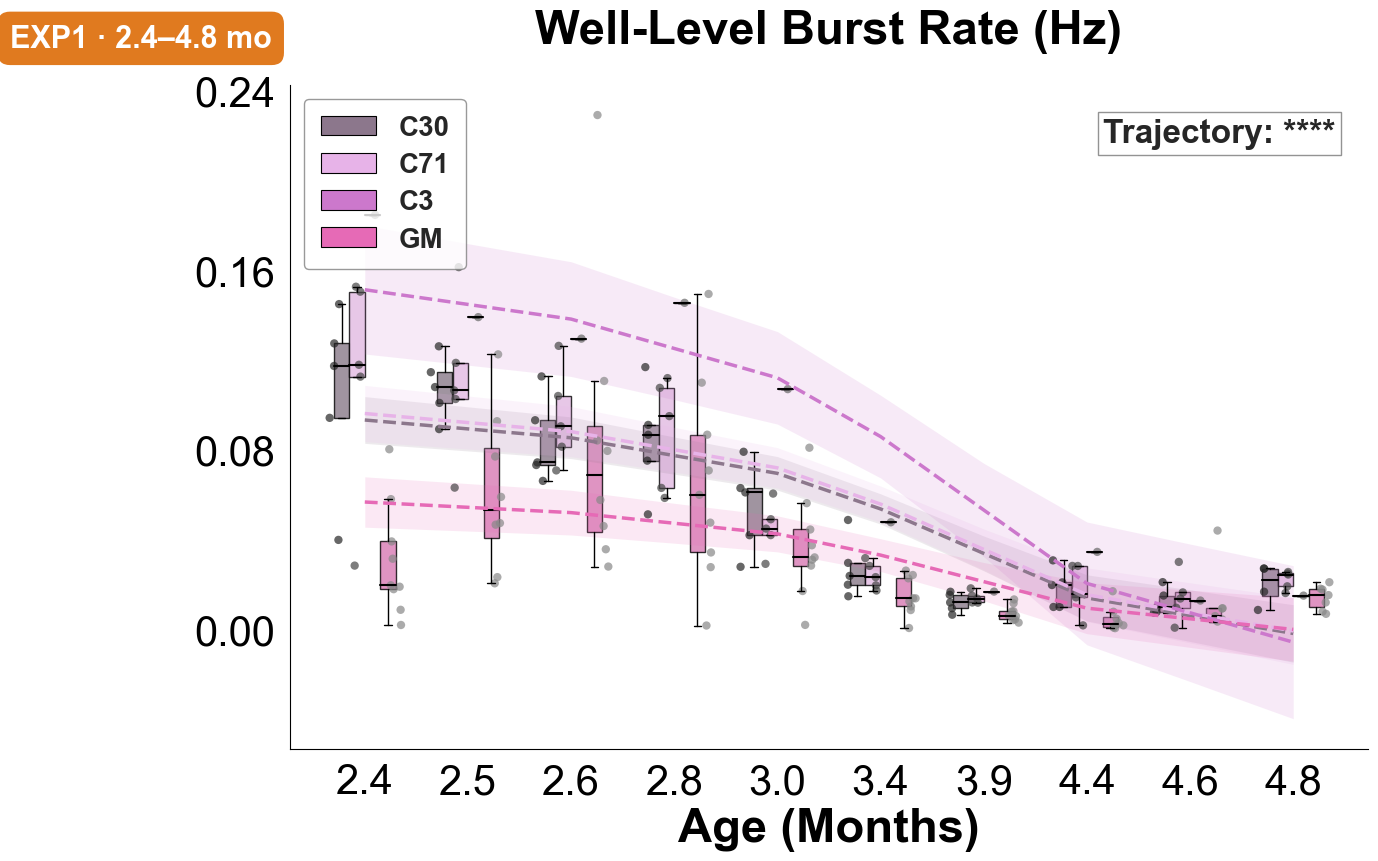

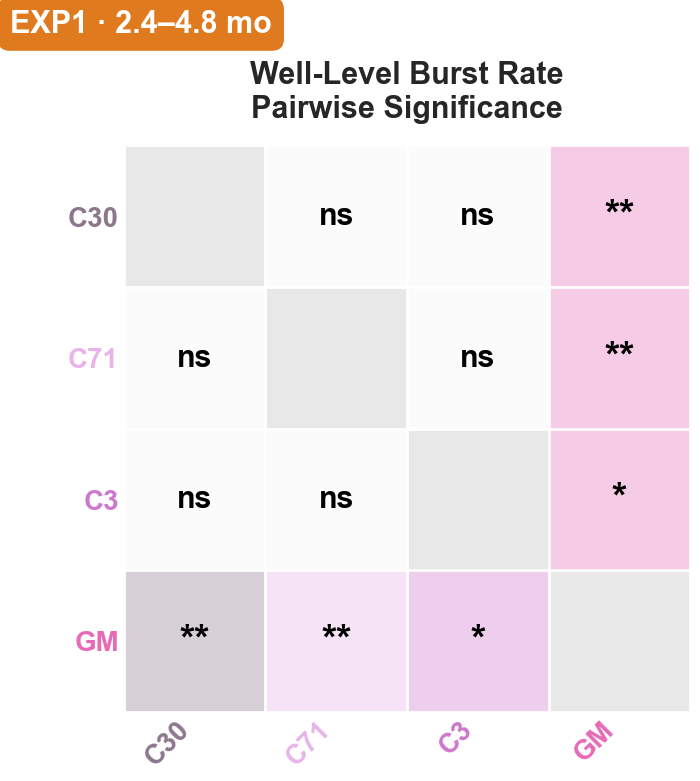

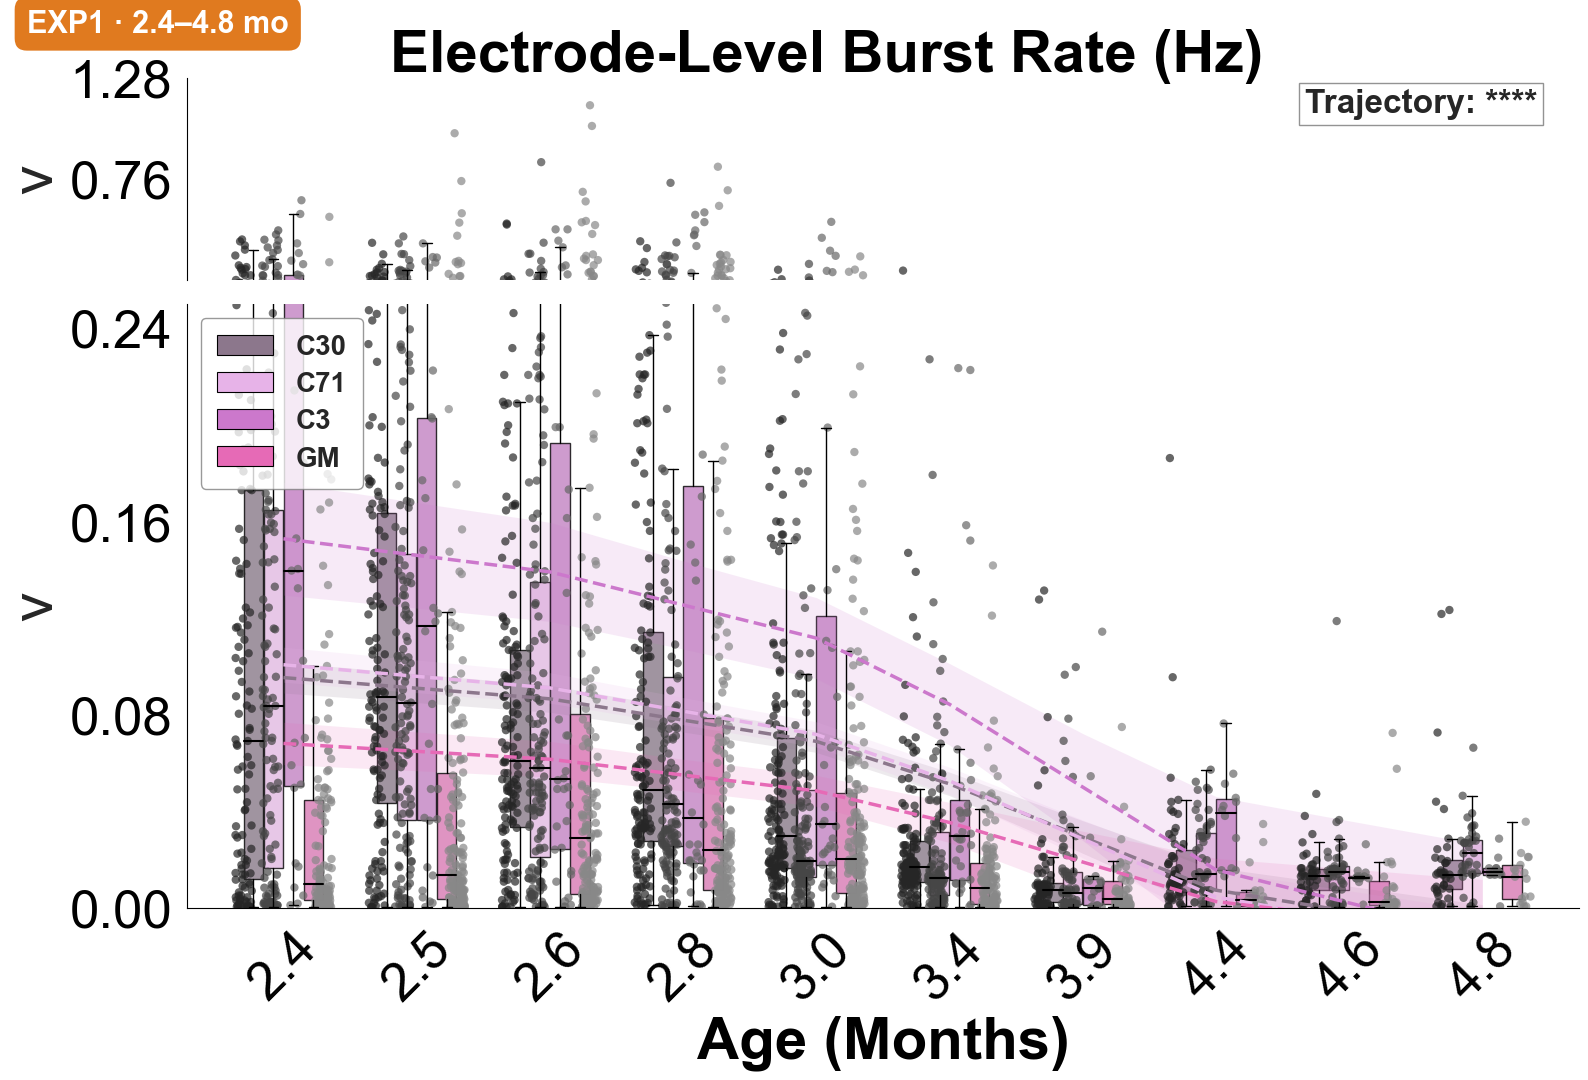

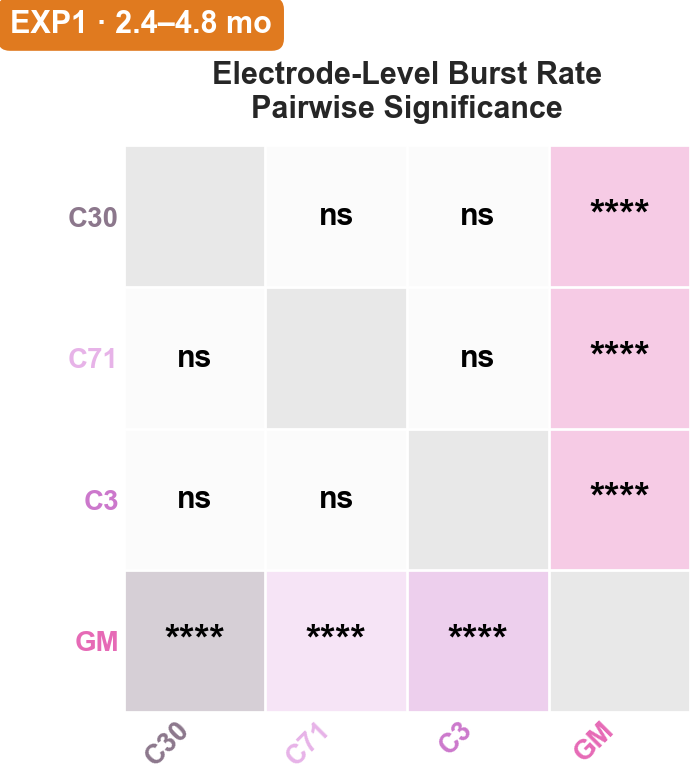


--- WELL-LEVEL BURST: mixed model, random intercept per well (n=192, wells=20) ---
       term        p  sig
      group  0.00368   **
        age 7.64e-48 ****
group x age 7.28e-05 ****
Overall group differences (Holm):
group1 group2    diff   p-adj sig
    C3    C30 -0.0405   0.633  ns
    C3    C71 -0.0385   0.633  ns
    C3     GM -0.0915  0.0152   *
   C30    C71 0.00204    0.91  ns
   C30     GM -0.0509 0.00822  **
   C71     GM  -0.053 0.00621  **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns     ****         ns      ****      ****
  2.5        ns        ns       ns         ns         *         *
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        ns        ns
  3.0        ns        ns       ns         ns        ns        ns
  3.4        ns        ns       ns         ns        ns        ns
  3.9        ns     


FEATURE: BURST


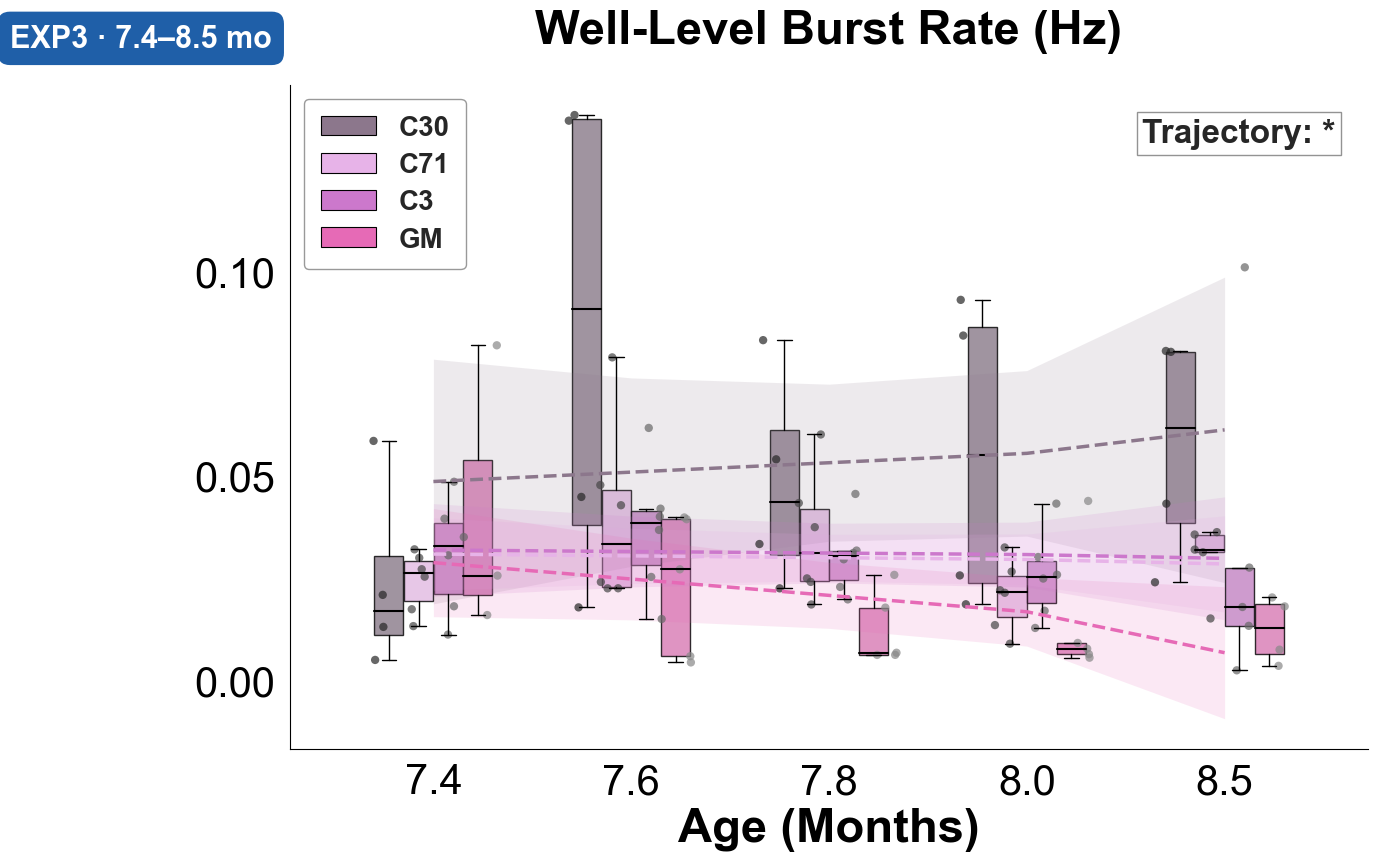

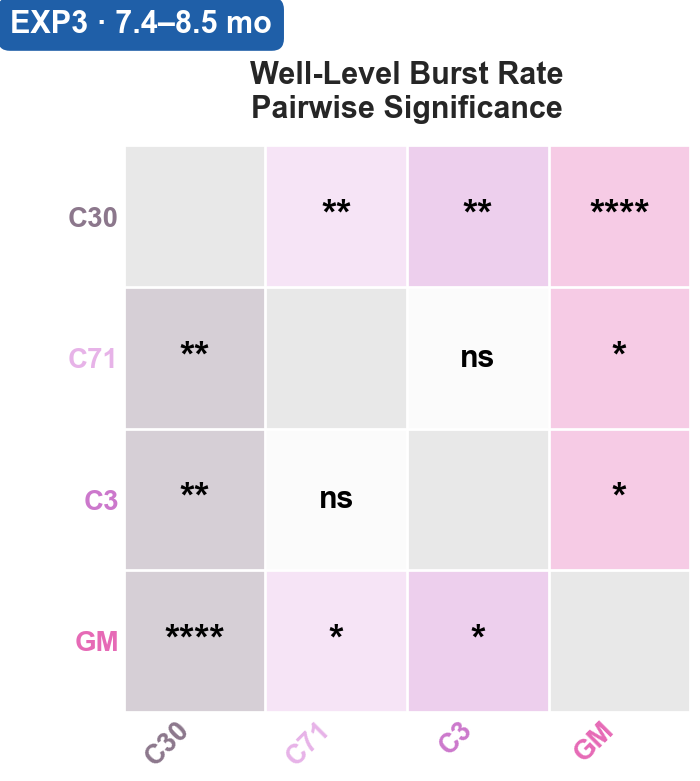

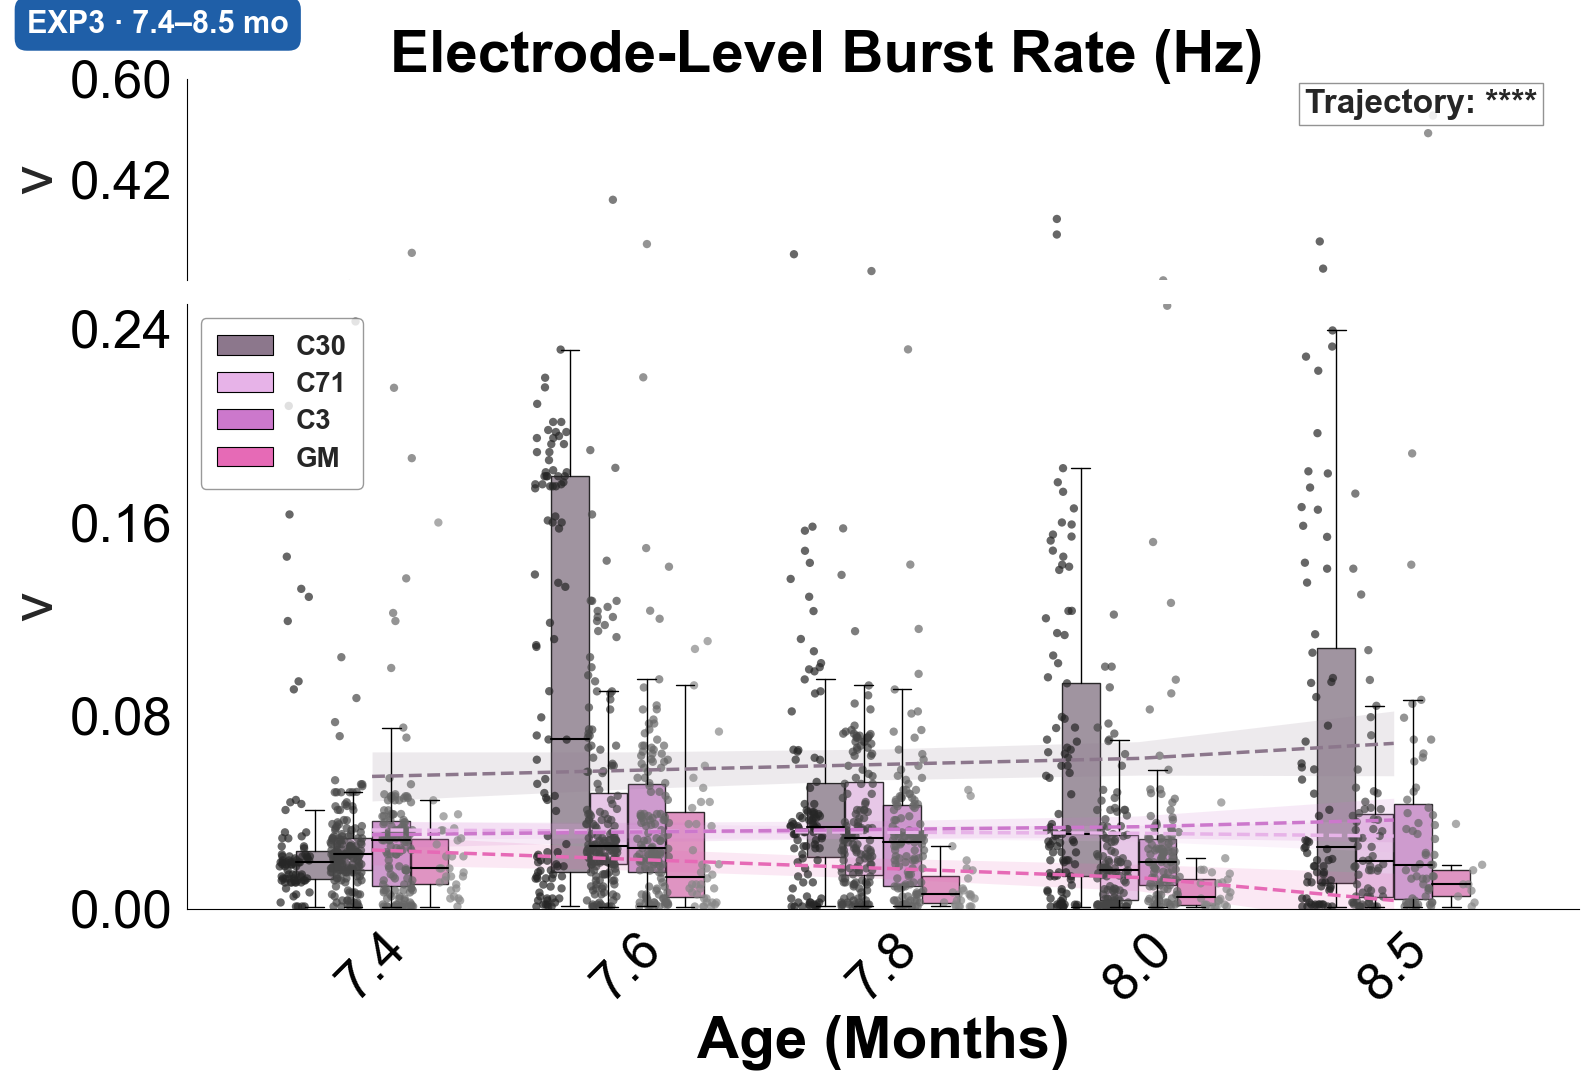

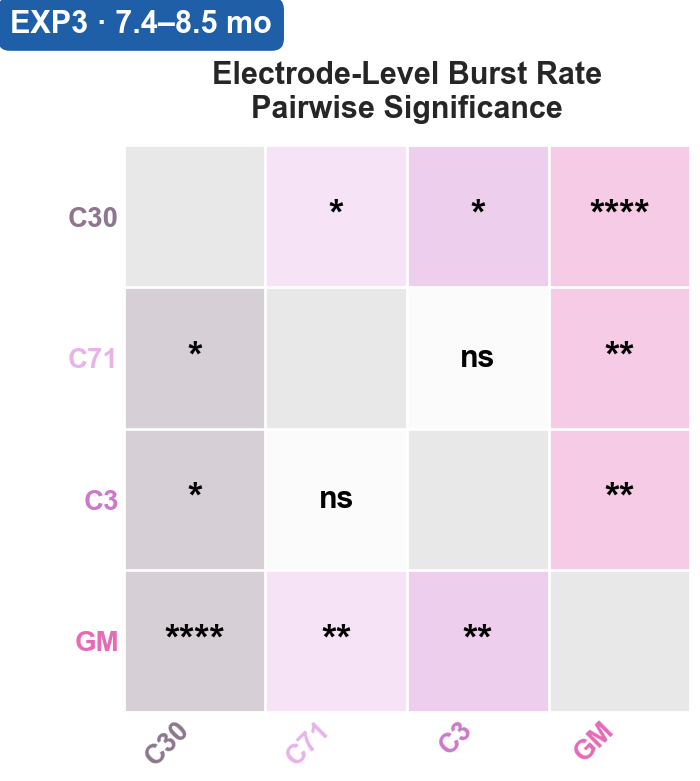


--- WELL-LEVEL BURST: mixed model, random intercept per well (n=100, wells=21) ---
       term        p sig
      group 0.000256 ***
        age   0.0129   *
group x age   0.0149   *
Overall group differences (Holm):
group1 group2      diff    p-adj  sig
    C3    C30     0.046  0.00876   **
    C3    C71 -0.000864    0.949   ns
    C3     GM   -0.0413   0.0125    *
   C30    C71   -0.0468  0.00876   **
   C30     GM   -0.0873 1.85e-07 ****
   C71     GM   -0.0405   0.0125    *
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6         *        ns       ns         ns       ***        ns
  7.8        ns        ns       ns         ns        **        ns
  8.0        ns        ns       ns         ns        **        ns
  8.5        ns        ns       ns         ns       ***        ns

--- ELECTRODE-LEVEL BURST: mixed model, random intercept per 

In [21]:
show_feature_by_experiment(datasets, "burst", "clone_trajectory", palette=MAOA_FIGURE_PALETTE)


--- GENERATING CLONE PLOTS FOR BURST ---


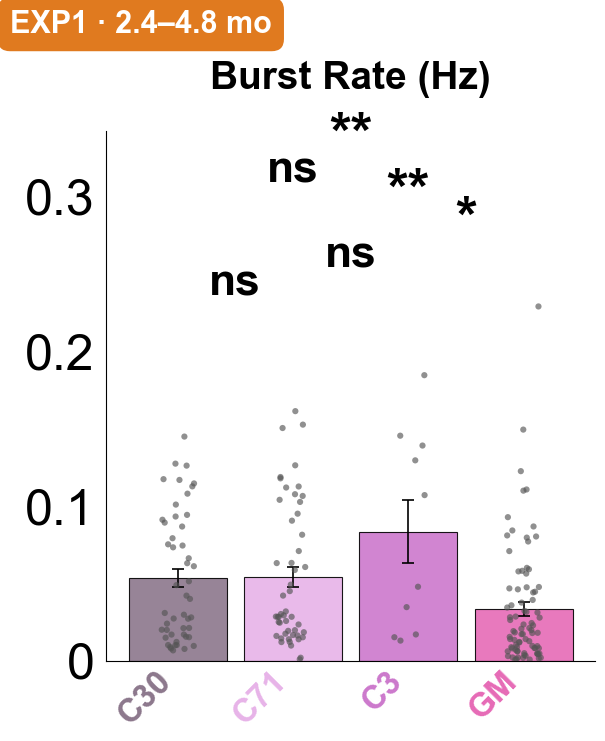

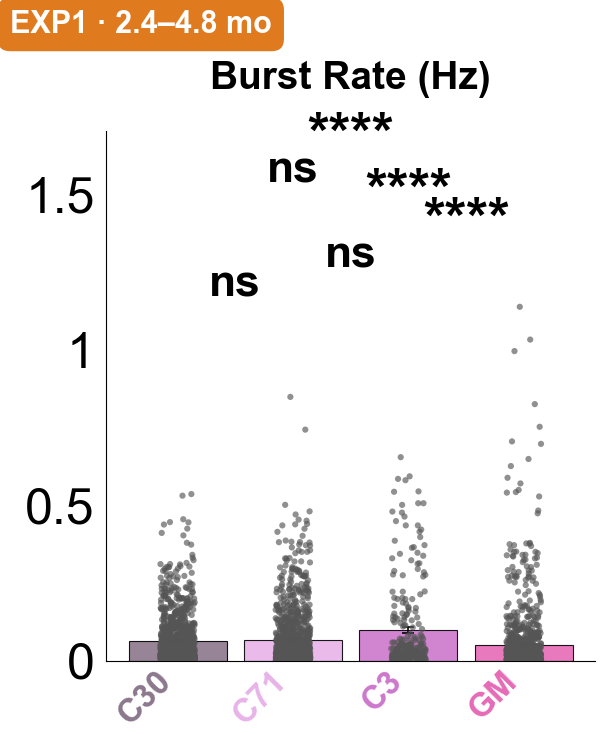


--- WELL-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=192, wells=20) ---
       term        p  sig
      group  0.00368   **
        age 7.64e-48 ****
group x age 7.28e-05 ****
Overall group differences (Holm):
group1 group2    diff   p-adj sig
    C3    C30 -0.0405   0.633  ns
    C3    C71 -0.0385   0.633  ns
    C3     GM -0.0915  0.0152   *
   C30    C71 0.00204    0.91  ns
   C30     GM -0.0509 0.00822  **
   C71     GM  -0.053 0.00621  **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns     ****         ns      ****      ****
  2.5        ns        ns       ns         ns         *         *
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        ns        ns
  3.0        ns        ns       ns         ns        ns        ns
  3.4        ns        ns       ns         ns        ns        ns
  3.9    


--- GENERATING CLONE PLOTS FOR BURST ---


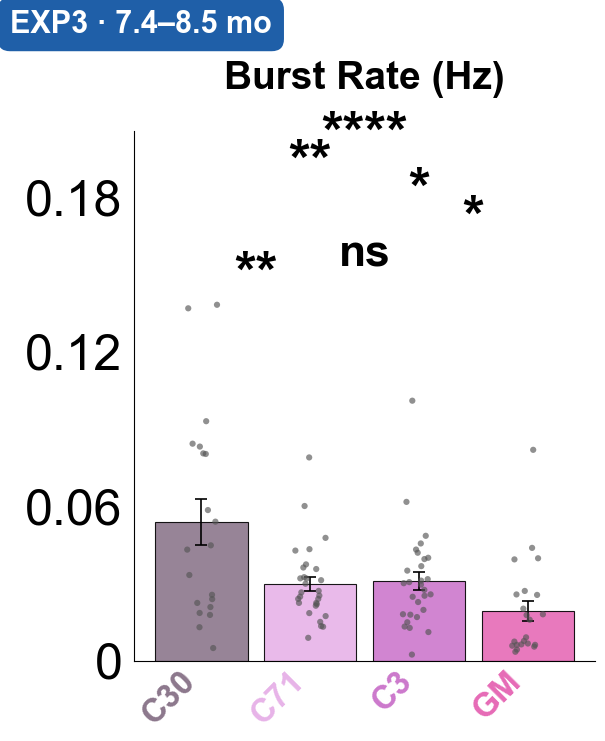

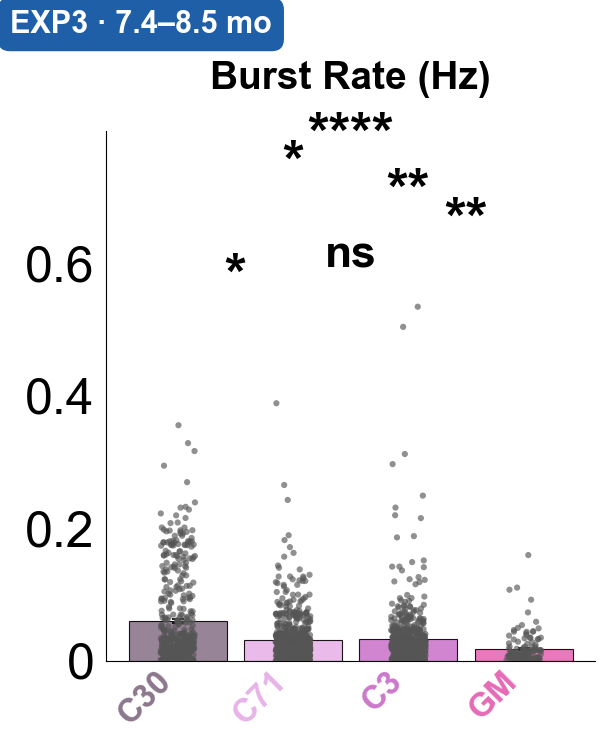


--- WELL-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=100, wells=21) ---
       term        p sig
      group 0.000256 ***
        age   0.0129   *
group x age   0.0149   *
Overall group differences (Holm):
group1 group2      diff    p-adj  sig
    C3    C30     0.046  0.00876   **
    C3    C71 -0.000864    0.949   ns
    C3     GM   -0.0413   0.0125    *
   C30    C71   -0.0468  0.00876   **
   C30     GM   -0.0873 1.85e-07 ****
   C71     GM   -0.0405   0.0125    *
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6         *        ns       ns         ns       ***        ns
  7.8        ns        ns       ns         ns        **        ns
  8.0        ns        ns       ns         ns        **        ns
  8.5        ns        ns       ns         ns       ***        ns

--- ELECTRODE-LEVEL BURST (BAR PLOT): mixed model,

In [22]:
show_feature_by_experiment(datasets, "burst", "clone_bars", palette=MAOA_FIGURE_PALETTE)

## 5.3 Network event rate by clone


FEATURE: NETWORK


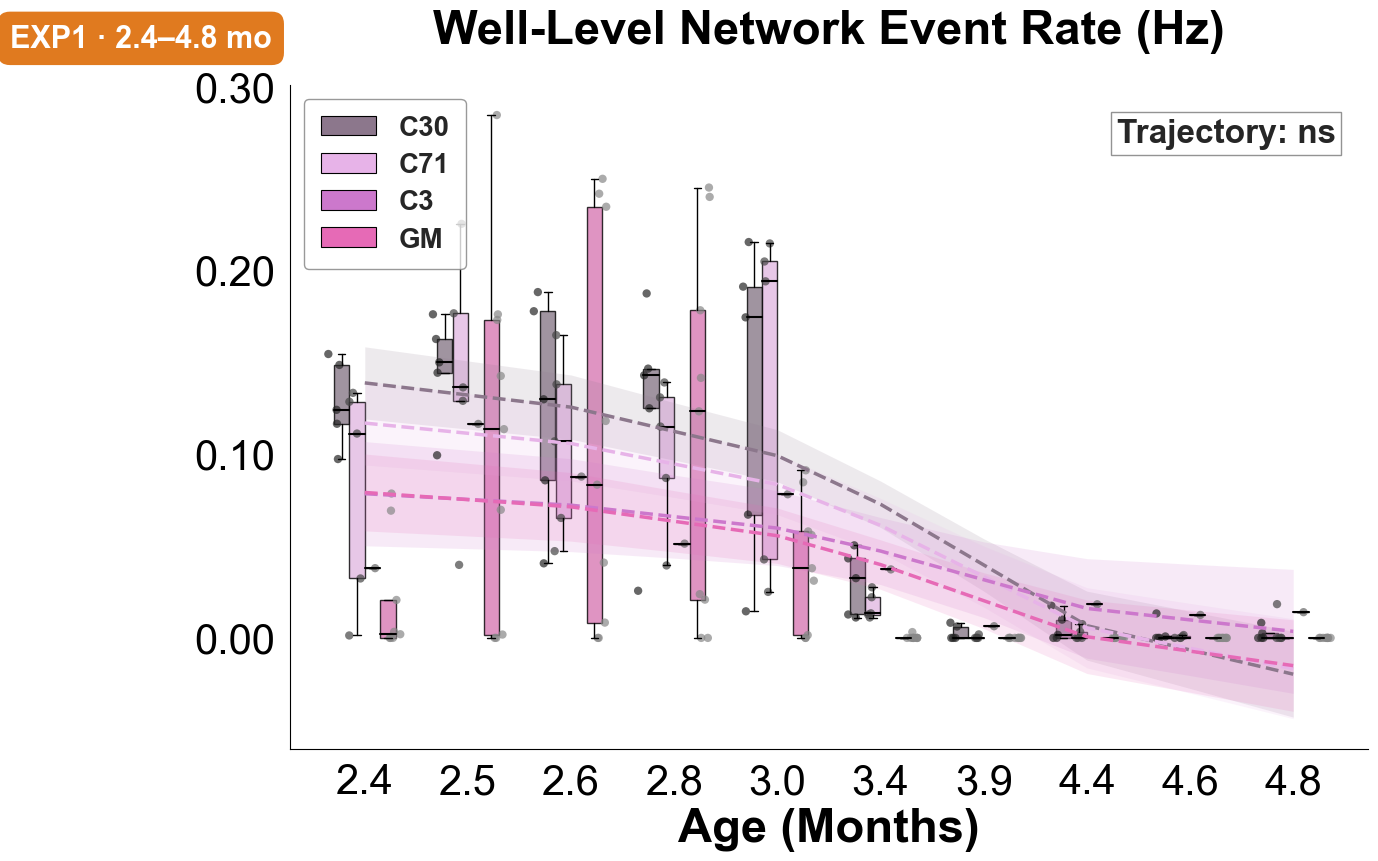

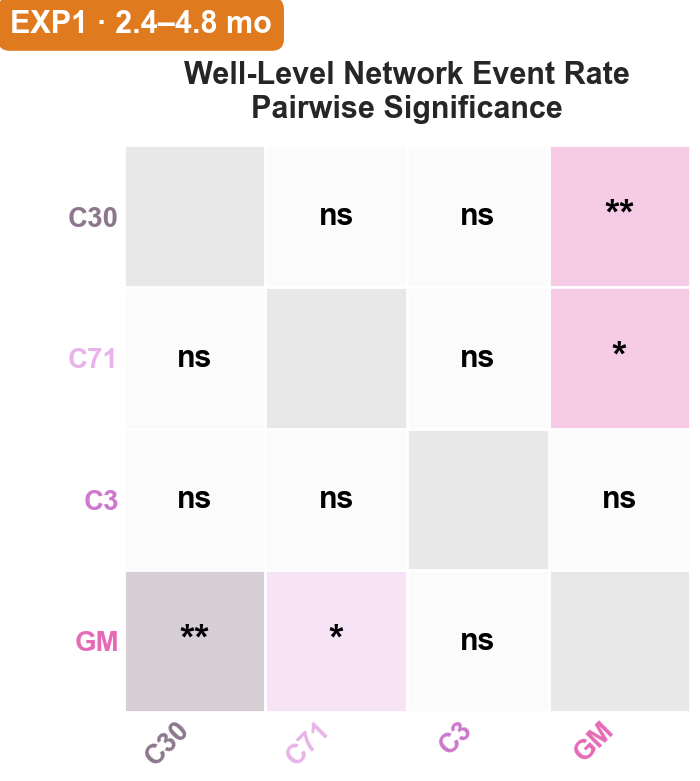


--- WELL-LEVEL NETWORK: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group  0.00967   **
        age 7.39e-41 ****
group x age    0.103   ns
Overall group differences (Holm):
group1 group2    diff   p-adj sig
    C3    C30  0.0297       1  ns
    C3    C71  0.0025       1  ns
    C3     GM -0.0716    0.76  ns
   C30    C71 -0.0272       1  ns
   C30     GM  -0.101 0.00167  **
   C71     GM -0.0741  0.0393   *
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns       ns         ns      ****        ns
  2.5        ns        ns       ns         ns        ns        ns
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        ns        ns
  3.0        ns        ns       ns         ns         *         *
  3.4        ns        ns       ns         ns        ns        ns
  3.9        ns   


FEATURE: NETWORK


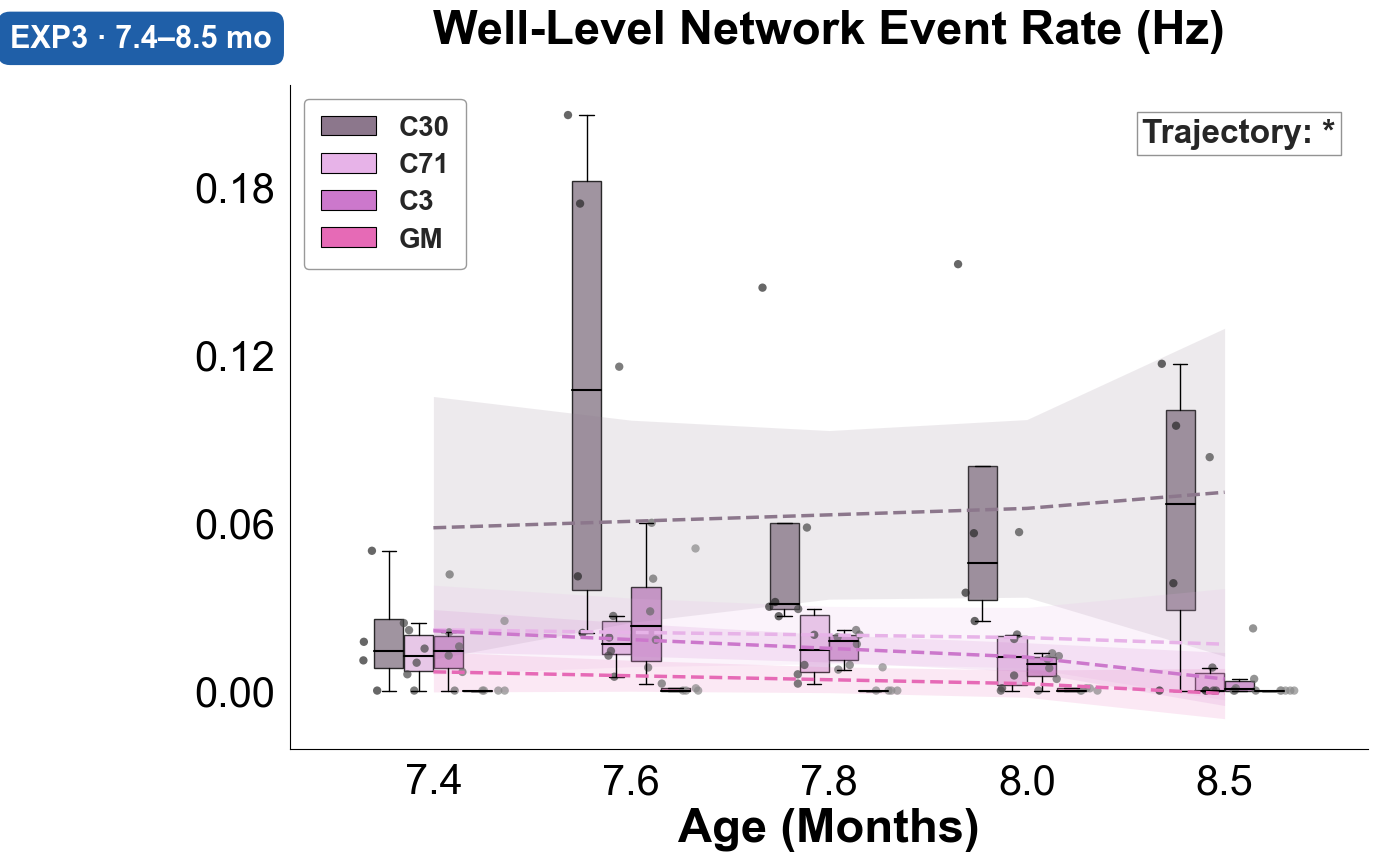

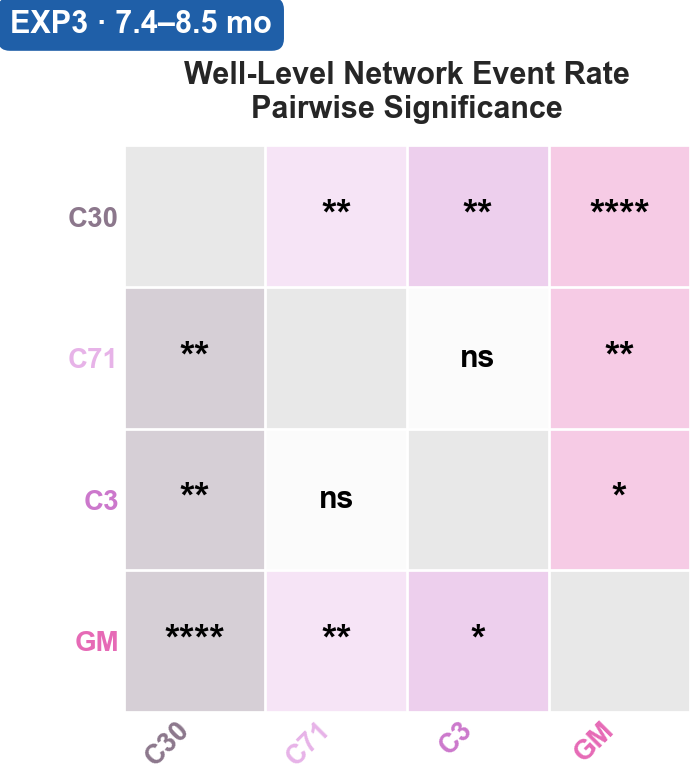


--- WELL-LEVEL NETWORK: mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 0.000131  ***
        age 7.97e-05 ****
group x age   0.0487    *
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30   0.108  0.00201   **
    C3    C71 0.00977    0.719   ns
    C3     GM -0.0788   0.0118    *
   C30    C71 -0.0983  0.00515   **
   C30     GM  -0.187 2.26e-08 ****
   C71     GM -0.0886  0.00593   **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6         *        ns       ns          *      ****        ns
  7.8        ns        ns       ns         ns       ***        ns
  8.0        **        ns       ns          *      ****        ns
  8.5        **        ns       ns          *       ***        ns


In [23]:
show_feature_by_experiment(datasets, "network", "clone_trajectory", palette=MAOA_FIGURE_PALETTE)


--- GENERATING CLONE PLOTS FOR NETWORK ---


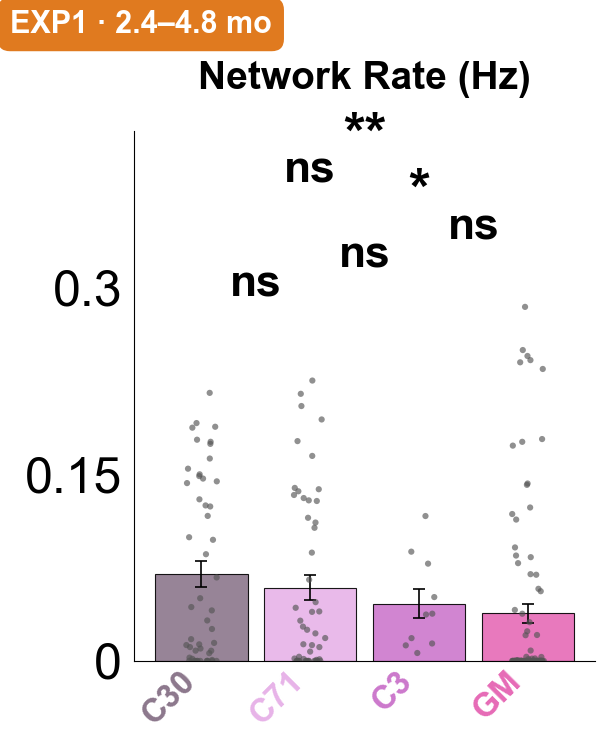


--- WELL-LEVEL NETWORK (BAR PLOT): mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group  0.00967   **
        age 7.39e-41 ****
group x age    0.103   ns
Overall group differences (Holm):
group1 group2    diff   p-adj sig
    C3    C30  0.0297       1  ns
    C3    C71  0.0025       1  ns
    C3     GM -0.0716    0.76  ns
   C30    C71 -0.0272       1  ns
   C30     GM  -0.101 0.00167  **
   C71     GM -0.0741  0.0393   *
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns       ns         ns      ****        ns
  2.5        ns        ns       ns         ns        ns        ns
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        ns        ns
  3.0        ns        ns       ns         ns         *         *
  3.4        ns        ns       ns         ns        ns        ns
  3.9  


--- GENERATING CLONE PLOTS FOR NETWORK ---


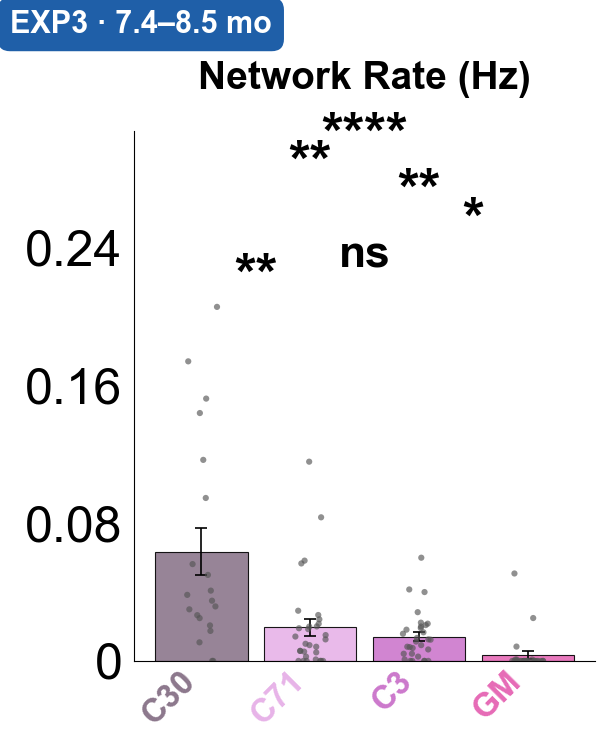


--- WELL-LEVEL NETWORK (BAR PLOT): mixed model, random intercept per well (n=105, wells=21) ---
       term        p  sig
      group 0.000131  ***
        age 7.97e-05 ****
group x age   0.0487    *
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30   0.108  0.00201   **
    C3    C71 0.00977    0.719   ns
    C3     GM -0.0788   0.0118    *
   C30    C71 -0.0983  0.00515   **
   C30     GM  -0.187 2.26e-08 ****
   C71     GM -0.0886  0.00593   **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6         *        ns       ns          *      ****        ns
  7.8        ns        ns       ns         ns       ***        ns
  8.0        **        ns       ns          *      ****        ns
  8.5        **        ns       ns          *       ***        ns


In [24]:
show_feature_by_experiment(datasets, "network", "clone_bars", palette=MAOA_FIGURE_PALETTE)

## 5.4 Synchrony index by clone


FEATURE: SYNCHRONY


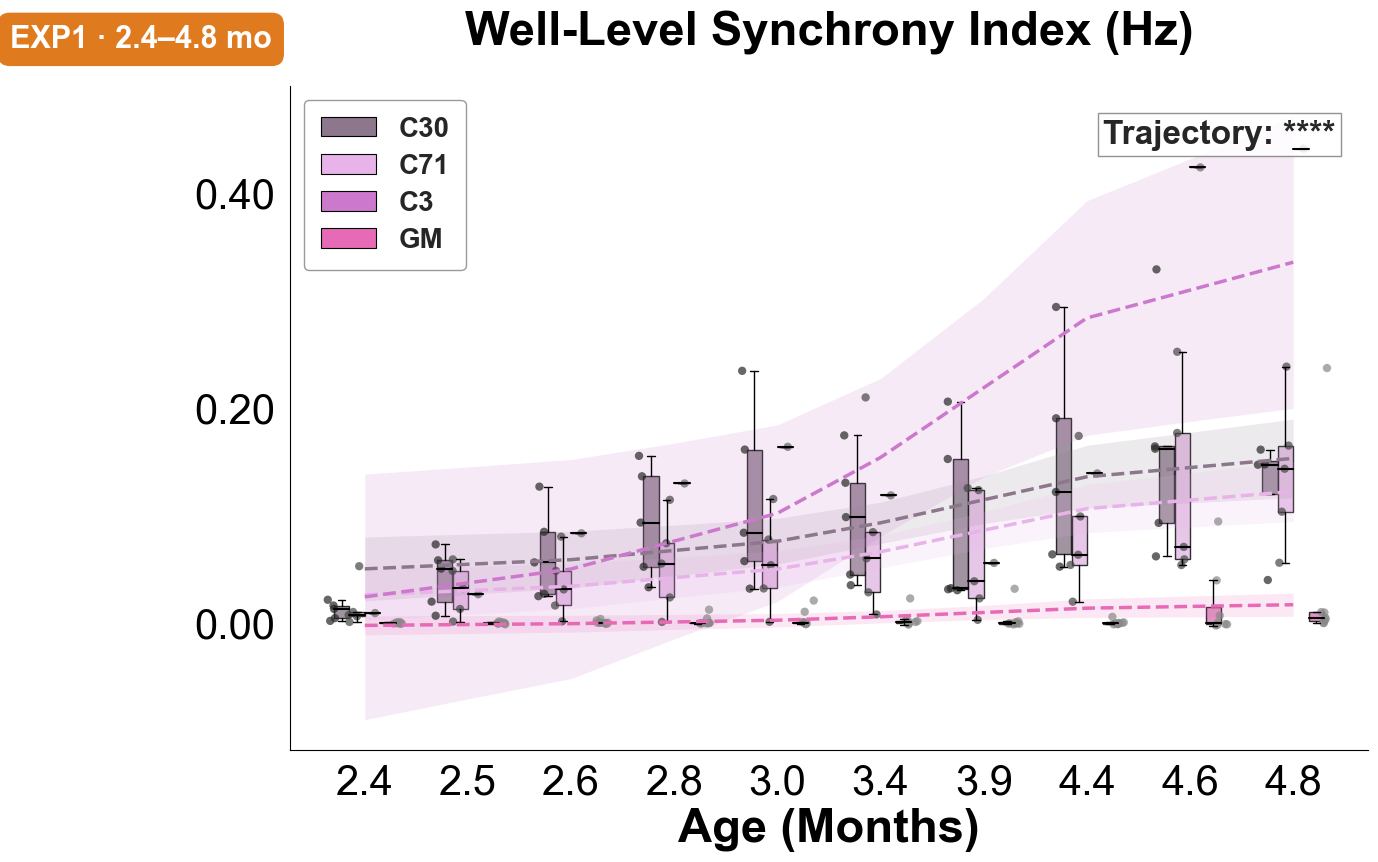

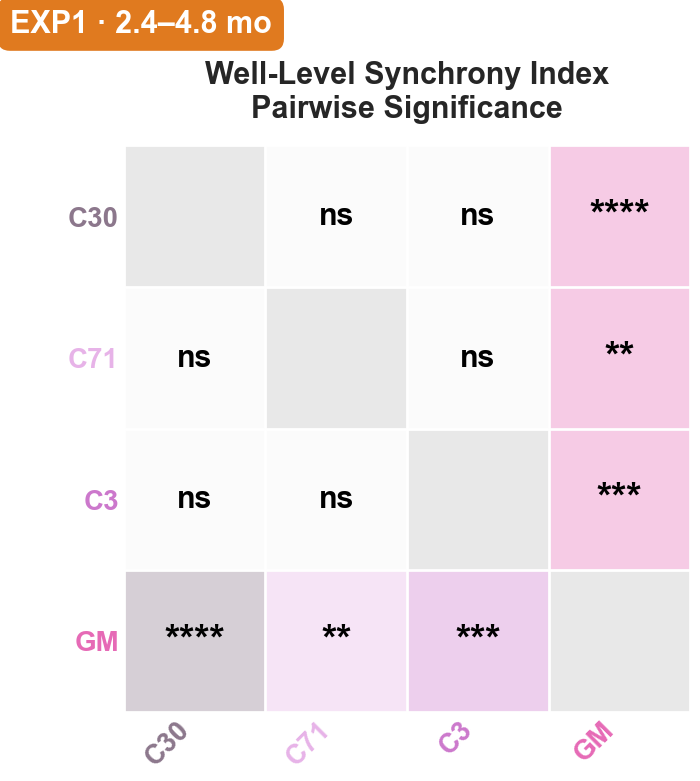


--- WELL-LEVEL SYNCHRONY: mixed model, random intercept per well (n=197, wells=20) ---
       term        p  sig
      group  0.00022  ***
        age 1.65e-12 ****
group x age 1.72e-20 ****
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30 -0.0525    0.313   ns
    C3    C71 -0.0801   0.0913   ns
    C3     GM   -0.14  0.00053  ***
   C30    C71 -0.0277    0.313   ns
   C30     GM -0.0872 1.32e-05 ****
   C71     GM -0.0596  0.00482   **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns       ns         ns        ns        ns
  2.5        ns        ns       ns         ns        ns        ns
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        **        ns
  3.0        ns        ns        *         ns       ***        ns
  3.4        ns        ns       ns         ns        **        ns
  


FEATURE: SYNCHRONY


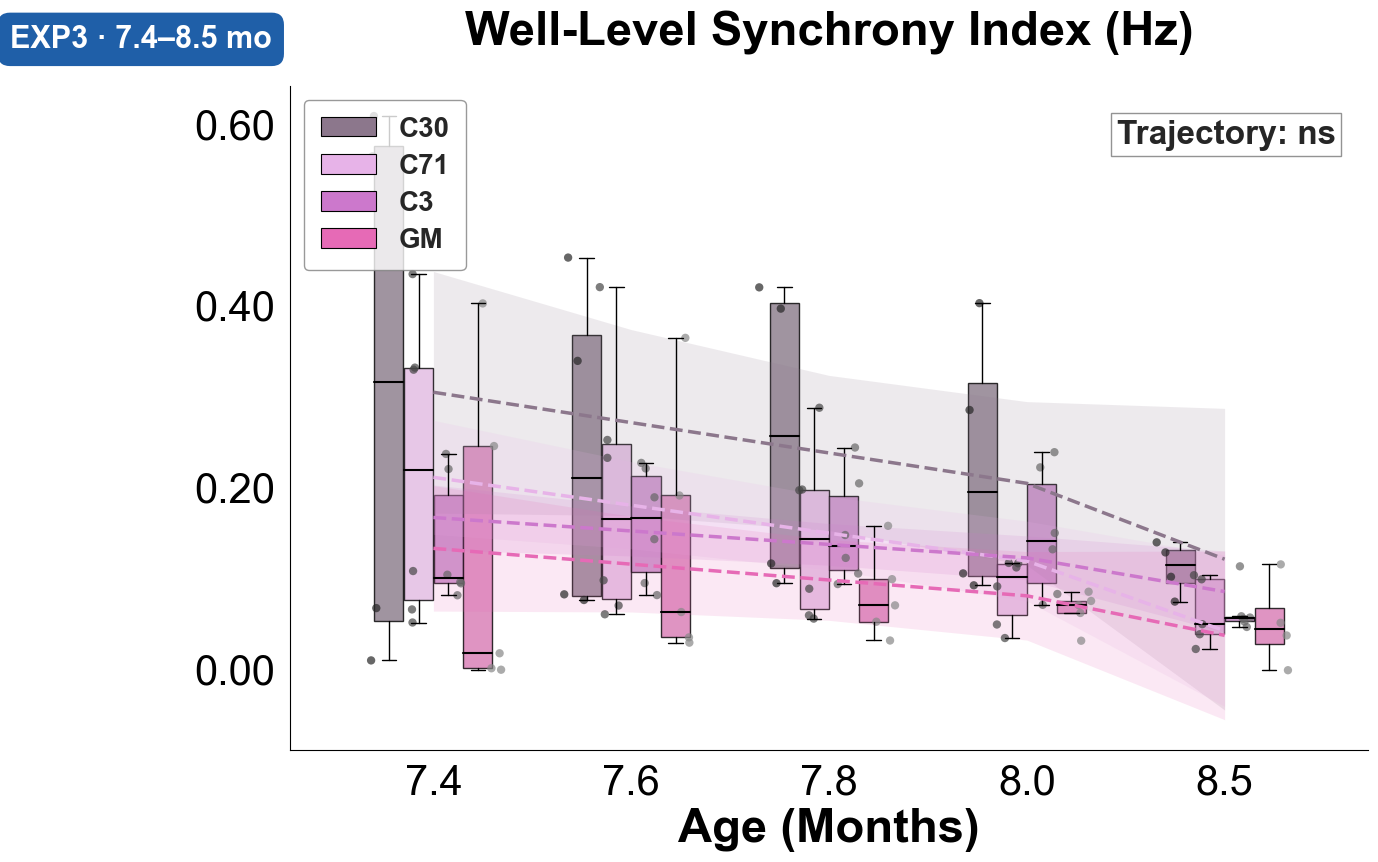


--- WELL-LEVEL SYNCHRONY: mixed model, random intercept per well (n=103, wells=21) ---
       term        p  sig
      group    0.102   ns
        age 9.99e-06 ****
group x age     0.56   ns
Overall group differences (Holm):
group1 group2    diff  p-adj sig
    C3    C30  0.0795  0.484  ns
    C3    C71  0.0116  0.786  ns
    C3     GM -0.0535  0.595  ns
   C30    C71 -0.0679  0.595  ns
   C30     GM  -0.133 0.0453   *
   C71     GM -0.0651  0.595  ns
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6        ns        ns       ns         ns        ns        ns
  7.8        ns        ns       ns         ns        ns        ns
  8.0        ns        ns       ns         ns        ns        ns
  8.5        ns        ns       ns         ns        ns        ns


In [25]:
show_feature_by_experiment(datasets, "synchrony", "clone_trajectory", palette=MAOA_FIGURE_PALETTE)


--- GENERATING CLONE PLOTS FOR SYNCHRONY ---


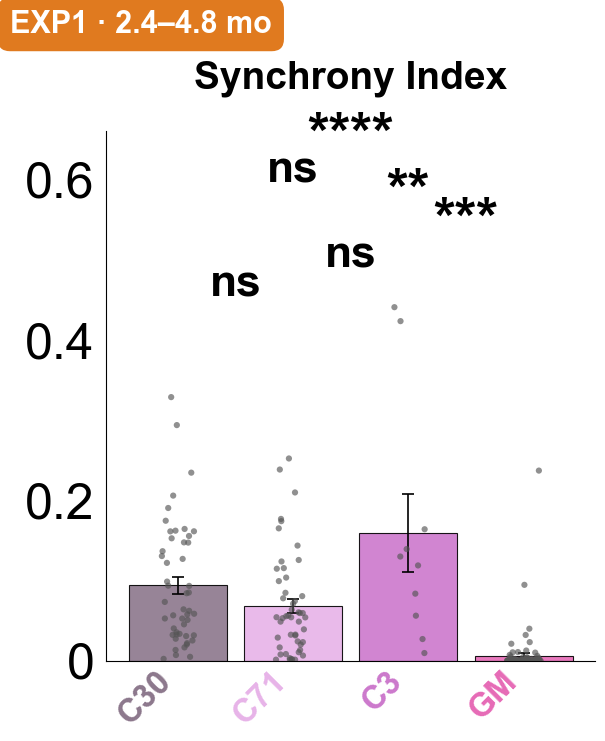


--- WELL-LEVEL SYNCHRONY (BAR PLOT): mixed model, random intercept per well (n=197, wells=20) ---
       term        p  sig
      group  0.00022  ***
        age 1.65e-12 ****
group x age 1.72e-20 ****
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30 -0.0525    0.313   ns
    C3    C71 -0.0801   0.0913   ns
    C3     GM   -0.14  0.00053  ***
   C30    C71 -0.0277    0.313   ns
   C30     GM -0.0872 1.32e-05 ****
   C71     GM -0.0596  0.00482   **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns       ns         ns        ns        ns
  2.5        ns        ns       ns         ns        ns        ns
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        **        ns
  3.0        ns        ns        *         ns       ***        ns
  3.4        ns        ns       ns         ns        **  


--- GENERATING CLONE PLOTS FOR SYNCHRONY ---


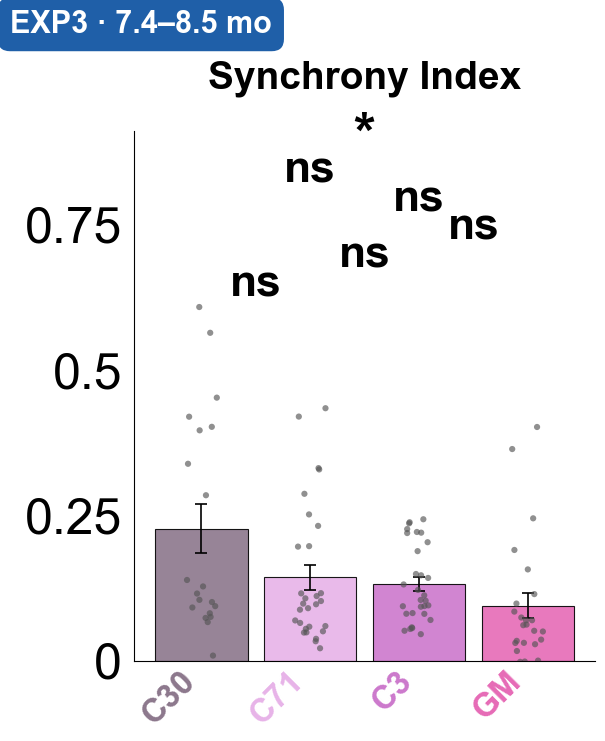


--- WELL-LEVEL SYNCHRONY (BAR PLOT): mixed model, random intercept per well (n=103, wells=21) ---
       term        p  sig
      group    0.102   ns
        age 9.99e-06 ****
group x age     0.56   ns
Overall group differences (Holm):
group1 group2    diff  p-adj sig
    C3    C30  0.0795  0.484  ns
    C3    C71  0.0116  0.786  ns
    C3     GM -0.0535  0.595  ns
   C30    C71 -0.0679  0.595  ns
   C30     GM  -0.133 0.0453   *
   C71     GM -0.0651  0.595  ns
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  7.4        ns        ns       ns         ns        ns        ns
  7.6        ns        ns       ns         ns        ns        ns
  7.8        ns        ns       ns         ns        ns        ns
  8.0        ns        ns       ns         ns        ns        ns
  8.5        ns        ns       ns         ns        ns        ns


In [26]:
show_feature_by_experiment(datasets, "synchrony", "clone_bars", palette=MAOA_FIGURE_PALETTE)